# Evaluación N.º 2 — Visualización de Datos de Transporte
## Operaciones de Aeronaves en aeródromos de Chile (JAC / DGAC), 2000–2026

**Pregunta principal.** ¿Cómo se distribuye y cómo ha evolucionado entre 2000 y 2026 la actividad de aterrizajes y despegues informada por la DGAC, según aeródromo, ámbito (doméstico / internacional) y tipo de actividad, y qué diferencias revela el shock de 2020?

| | Pregunta secundaria |
|---|---|
| **P1** | ¿Qué aeródromos concentran las operaciones en 2025 (último año completo) y qué proporción corresponde a tráfico internacional? |
| **P2** | ¿Cómo evolucionó el volumen mensual de operaciones entre 2000 y 2026, y existe un patrón estacional estable? |
| **P3** | ¿En qué se diferencian los tipos de actividad (pasajeros, instrucción, privada, carga…) en el tamaño de aeronave (PMD) y en su horario de operación? |

**H1 (exploratoria, no es conclusión).** Tras la caída de 2020, el tráfico internacional se recuperó más lentamente que el doméstico: tardó más años en volver al nivel de 2019.

La investigación de la fuente (Partes I y II) está en [`docs/01_investigacion_fuente.md`](../docs/01_investigacion_fuente.md).

**Estructura:** 1 Importaciones · 2 Configuración · 3 Carga · 4 Perfilamiento · 5 Calidad · 6 Limpieza · 7 Transformaciones · 8 Dimensionalidad · 9 Visualizaciones · 10 Benchmark · 11 Validación · 12 Interpretación · 13 Conclusiones

## 1. Importaciones

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import pyarrow.parquet as pq

## 2. Configuración

El notebook se ejecuta desde `notebooks/`; la raíz del proyecto se agrega al `sys.path` para importar los módulos de `src/`.

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import preparacion as prep
import estilo as st

st.aplicar_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RAW, PROCESSED, FIGURES = prep.RAW, prep.PROCESSED, st.FIGURES
print("pandas", pd.__version__, "| seaborn", sns.__version__)
print("Archivos originales:", sorted(p.name for p in RAW.iterdir() if p.is_file()))

pandas 3.0.6 | seaborn 0.13.2
Archivos originales: ['.gitkeep', 'bitacora-vuelos.parquet', 'dim_actividad_dgac.csv', 'dim_aerolinea.csv', 'dim_aeropuerto.csv', 'manifest.json', 'operaciones-aeropuertos.csv']


## 3. Carga

Se verifica primero la integridad de los archivos originales contra el manifiesto de procedencia (`data/raw/manifest.json`). Si falta el parquet (no se versiona por superar los 100 MB de GitHub) se descarga con `python src/download_data.py`.

In [3]:
import json, hashlib

manifest = json.loads((RAW / "manifest.json").read_text("utf-8"))
for nombre, meta in manifest.items():
    if nombre.startswith("_"):
        continue
    path = RAW / nombre
    if not path.exists():
        raise FileNotFoundError(f"Falta {nombre}: ejecute `python src/download_data.py`")
    h = hashlib.sha256(path.read_bytes()).hexdigest()
    estado = "OK" if h == meta["sha256"] else "VERSIÓN DISTINTA (la fuente se actualiza mensualmente)"
    print(f"{nombre:32s} {path.stat().st_size/1e6:8.2f} MB  {estado}")

bitacora-vuelos.parquet            138.25 MB  OK
operaciones-aeropuertos.csv          0.29 MB  OK
dim_aeropuerto.csv                   0.10 MB  OK
dim_aerolinea.csv                    0.01 MB  OK
dim_actividad_dgac.csv               0.00 MB  OK


Metadatos del parquet: se lee el esquema sin cargar los datos.

In [4]:
meta = pq.ParquetFile(RAW / "bitacora-vuelos.parquet")
print(meta.metadata)
print(meta.schema_arrow)

  created_by: Polars
  num_columns: 12
  num_rows: 11163791
  num_row_groups: 91
  format_version: 1.0
  serialized_size: 98251
dt_operacion: timestamp[us, tz=America/Santiago]
aeropuerto_oaci: large_string
tipo_operacion: large_string
aeropuerto_dgac_orig_dest: large_string
aerolinea_dgac: large_string
numero_vuelo: large_string
actividad_cod: large_string
matricula: large_string
modelo_avion: large_string
modelo_avion_desc: large_string
es_internacional: bool
pmd: decimal128(10, 5)


La bitácora se carga con las columnas de texto como **categóricas** (diccionario Arrow). Con `pd.read_parquet` por defecto ocupa ≈ 2,5 GB en memoria; como categóricas, ≈ 360 MB, sin pérdida de información.

In [5]:
t0 = time.perf_counter()
raw = prep.cargar_bitacora()
print(f"Carga: {time.perf_counter()-t0:.1f} s | memoria: {raw.memory_usage(deep=True).sum()/1e6:,.0f} MB")

resumen = pd.read_csv(prep.RESUMEN)
dim_aer = prep.cargar_dim_aeropuerto()
dim_act = prep.cargar_dim_actividad()

Carga: 7.4 s | memoria: 359 MB


### 3.1 Comparación de formatos (Parte VI)

**Los dos recursos publicados no son equivalentes**: el Parquet es la bitácora a nivel de operación (11,2 M filas, 12 columnas) y el CSV es un resumen mensual por aeródromo y ámbito (16 mil filas, 4 columnas, sin sobrevuelos). Comparar sus tiempos de carga directamente sería una comparación artificial: mediría el tamaño de los datos, no el formato.

Para una comparación justa se escribe **el mismo subconjunto** (operaciones de 2019 de la bitácora original, todas las columnas) en ambos formatos, en una carpeta temporal fuera del control de versiones, y se miden ambos con idéntico contenido.

In [6]:
bench_dir = PROCESSED / "_benchmark_formatos"
bench_dir.mkdir(parents=True, exist_ok=True)
y2019 = raw[raw["dt_operacion"].dt.year == 2019].copy()
for c in prep.TEXT_COLS:
    y2019[c] = y2019[c].astype("string")
y2019.to_csv(bench_dir / "bitacora_2019.csv", index=False)
y2019.to_parquet(bench_dir / "bitacora_2019.parquet", compression="zstd", index=False)

def medir(lector, path, n=3):
    tiempos = []
    for _ in range(n):
        t0 = time.perf_counter(); d = lector(path); tiempos.append(time.perf_counter() - t0)
    return d, min(tiempos)

d_csv, t_csv = medir(pd.read_csv, bench_dir / "bitacora_2019.csv")
d_pq, t_pq = medir(pd.read_parquet, bench_dir / "bitacora_2019.parquet")

comp_formatos = pd.DataFrame({
    "tamaño_archivo_MB": [(bench_dir / f"bitacora_2019.{e}").stat().st_size / 1e6 for e in ("csv", "parquet")],
    "tiempo_carga_s": [t_csv, t_pq],
    "memoria_MB": [d.memory_usage(deep=True).sum() / 1e6 for d in (d_csv, d_pq)],
    "filas": [len(d_csv), len(d_pq)],
}, index=["CSV", "Parquet (zstd)"])
comp_formatos

,tamaño_archivo_MB,tiempo_carga_s,memoria_MB,filas
CSV,41.65,1.27,77.40,528890
Parquet (zstd),6.40,0.06,63.70,528890


Tipos inferidos por cada lector sobre el mismo contenido:

In [7]:
pd.DataFrame({"CSV": d_csv.dtypes.astype(str), "Parquet": d_pq.dtypes.astype(str)})

,CSV,Parquet
dt_operacion,str,"datetime64[us, America/Santiago]"
aeropuerto_oaci,str,string
tipo_operacion,str,string
aeropuerto_dgac_orig_dest,str,string
aerolinea_dgac,str,string
numero_vuelo,str,string
actividad_cod,str,string
matricula,str,string
modelo_avion,str,string
modelo_avion_desc,str,string


In [8]:
del d_csv, d_pq, y2019

**¿Qué formato conviene?** Para la bitácora, **Parquet**: el archivo es varias veces más pequeño, carga más rápido y —lo más importante para la calidad— **conserva los tipos**: la fecha llega como `datetime` con zona horaria, `es_internacional` como booleano y `pmd` como numérico. El CSV entrega la fecha como texto (hay que volver a parsearla con `parse_dates` y tratar la zona horaria a mano) y el tipo de cada columna depende de la inferencia sobre su contenido: aquí `actividad_cod` y `numero_vuelo` quedaron como texto sólo porque mezclan letras y dígitos; un subconjunto con únicamente dígitos se habría leído como entero (perdiendo, por ejemplo, ceros a la izquierda). El CSV sólo es preferible para tablas pequeñas que se abren en Excel o se revisan a mano, como el resumen mensual oficial (285 KB), y por eso las tablas agregadas de este proyecto se exportan en CSV.

## 4. Perfilamiento

In [9]:
raw.head()

,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
0,1999-12-31 21:00:00-03:00,SCEL,A,SPIM,LAN,631,U,CCCDM,B763,767-352ER,True,187.00
1,1999-12-31 21:00:00-03:00,SCTC,D,SCUG,6,0,P,CCSPC,C172,172B,False,1.00
2,1999-12-31 21:04:00.001000-03:00,SCEL,A,SCTC,LAN,4248,U,CCCHS,EC35,EC-135 T2,False,2.84
3,1999-12-31 21:08:00-03:00,SCFA,A,SCEL,LCO,2395,U,CCCYK,B732,737-205,False,53.00
4,1999-12-31 21:08:00-03:00,SCFA,A,SCEL,LCO,2394,U,CCCYK,B732,737-205,False,53.00


In [10]:
raw.tail()

,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
11163786,2026-09-30 20:53:00-03:00,SCSE,D,SCCF,JAT,136,U,CCDIN,A320,A320-271N,False,77.00
11163787,2026-09-30 20:54:00-03:00,SCCF,D,SCEL,LAN,1859,U,CCBEO,A321,A-321-211,False,89.00
11163788,2026-09-30 20:55:00-03:00,SCEL,A,SCQP,LAN,34,U,CCBEI,A321,A-321-211,False,89.00
11163789,2026-09-30 20:57:00-03:00,SCIE,D,SCEL,LAN,10,U,CCBEL,A321,A-321-211,False,89.00
11163790,2026-09-30 20:58:00-03:00,SCCF,A,SCSE,JAT,134,U,CCAWB,A320,A-320-232,False,78.00


In [11]:
raw.sample(5, random_state=42)

,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
10816381,2026-02-07 23:40:00-03:00,SCEL,A,SCAR,SKU,307,U,CCDBL,A320,A320-251N,False,79.00
1338062,2003-12-30 15:59:00-03:00,SCTB,D,SCTB,6,0,P,CCKIJ,C152,152,False,0.76
2619068,2007-10-14 12:32:00-03:00,SCFA,D,SCFA,6,,P,CCNAC,P28A,PA-28-180 CHERO,False,1.09
596927,2001-11-11 20:23:00-03:00,SCTI,A,SCTB,3R,1,O,CCCRZ,PA38,PA-38-112,False,0.76
5873112,2015-12-08 14:11:00-03:00,SCJO,D,SCJO,21R,0,O,CCCXS,C206,206,False,1.73


In [12]:
print("shape:", raw.shape)
print("columnas:", list(raw.columns))
raw.dtypes

shape: (11163791, 12)
columnas: ['dt_operacion', 'aeropuerto_oaci', 'tipo_operacion', 'aeropuerto_dgac_orig_dest', 'aerolinea_dgac', 'numero_vuelo', 'actividad_cod', 'matricula', 'modelo_avion', 'modelo_avion_desc', 'es_internacional', 'pmd']


dt_operacion                 datetime64[us, America/Santiago]
aeropuerto_oaci                                      category
tipo_operacion                                       category
aeropuerto_dgac_orig_dest                            category
aerolinea_dgac                                       category
numero_vuelo                                         category
actividad_cod                                        category
matricula                                            category
modelo_avion                                         category
modelo_avion_desc                                    category
es_internacional                                         bool
pmd                                                   float64
dtype: object

In [13]:
raw.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 11163791 entries, 0 to 11163790
Data columns (total 12 columns):
 #   Column                     Dtype                           
---  ------                     -----                           
 0   dt_operacion               datetime64[us, America/Santiago]
 1   aeropuerto_oaci            category                        
 2   tipo_operacion             category                        
 3   aeropuerto_dgac_orig_dest  category                        
 4   aerolinea_dgac             category                        
 5   numero_vuelo               category                        
 6   actividad_cod              category                        
 7   matricula                  category                        
 8   modelo_avion               category                        
 9   modelo_avion_desc          category                        
 10  es_internacional           bool                            
 11  pmd                        float64            

In [14]:
raw.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
dt_operacion,11163791,NaN,NaN,NaN,2014-09-10 17:16:20.947549-03:00,1999-12-31 21:00:00-03:00,2008-03-27 19:51:00.000500-03:00,2015-03-28 18:57:00.001000-03:00,2021-09-05 14:33:00.000500-03:00,2026-09-30 20:58:00-03:00,NaN
aeropuerto_oaci,11163791,69,SCEL,3146276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_operacion,11163791,4,A,5356831,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aeropuerto_dgac_orig_dest,11163791,1671,SCEL,1713457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aerolinea_dgac,11163791,2568,LAN,1613920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
numero_vuelo,10681646,7442,,1698594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
actividad_cod,11163791,26,U,6157517,NaN,NaN,NaN,NaN,NaN,NaN,NaN
matricula,11163791,13835,CCBAY,48564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modelo_avion,11163791,1286,A320,1769307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modelo_avion_desc,11163791,2325,A-321-211,595007,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
raw.nunique().sort_values()

es_internacional                   2
tipo_operacion                     4
actividad_cod                     26
aeropuerto_oaci                   69
pmd                              785
modelo_avion                    1286
aeropuerto_dgac_orig_dest       1671
modelo_avion_desc               2325
aerolinea_dgac                  2568
numero_vuelo                    7442
matricula                      13835
dt_operacion                 6527475
dtype: int64

### 4.1 Perfil construido

In [16]:
TIPO_VARIABLE = {
    "dt_operacion": "temporal", "aeropuerto_oaci": "categórica", "tipo_operacion": "categórica",
    "aeropuerto_dgac_orig_dest": "categórica", "aerolinea_dgac": "categórica", "numero_vuelo": "categórica (código)",
    "actividad_cod": "categórica", "matricula": "categórica (identificador)", "modelo_avion": "categórica",
    "modelo_avion_desc": "textual", "es_internacional": "booleana", "pmd": "numérica",
}
perfil = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "tipo": pd.Series(TIPO_VARIABLE),
    "cardinalidad": raw.nunique(),
    "nulos": raw.isna().sum(),
    "nulos_%": (raw.isna().mean() * 100).round(2),
})
print(f"Registros: {len(raw):,} | Columnas: {raw.shape[1]}")
print("Numéricas:", [c for c, t in TIPO_VARIABLE.items() if t == "numérica"])
print("Temporales:", [c for c, t in TIPO_VARIABLE.items() if t == "temporal"])
print("Categóricas/booleanas:", [c for c, t in TIPO_VARIABLE.items() if t not in ("numérica", "temporal")])
perfil

Registros: 11,163,791 | Columnas: 12
Numéricas: ['pmd']
Temporales: ['dt_operacion']
Categóricas/booleanas: ['aeropuerto_oaci', 'tipo_operacion', 'aeropuerto_dgac_orig_dest', 'aerolinea_dgac', 'numero_vuelo', 'actividad_cod', 'matricula', 'modelo_avion', 'modelo_avion_desc', 'es_internacional']


,dtype,tipo,cardinalidad,nulos,nulos_%
dt_operacion,"datetime64[us, America/Santiago]",temporal,6527475,0,0.00
aeropuerto_oaci,category,categórica,69,0,0.00
tipo_operacion,category,categórica,4,0,0.00
aeropuerto_dgac_orig_dest,category,categórica,1671,0,0.00
aerolinea_dgac,category,categórica,2568,0,0.00
numero_vuelo,category,categórica (código),7442,482145,4.32
actividad_cod,category,categórica,26,0,0.00
matricula,category,categórica (identificador),13835,0,0.00
modelo_avion,category,categórica,1286,0,0.00
modelo_avion_desc,category,textual,2325,0,0.00


## 5. Auditoría de calidad

### 5.1 Ausentes y vacíos

`isna()` no detecta todo: varias columnas usan **cadenas vacías o espacios** como "sin dato".

In [17]:
raw.isna().sum()

dt_operacion                      0
aeropuerto_oaci                   0
tipo_operacion                    0
aeropuerto_dgac_orig_dest         0
aerolinea_dgac                    0
numero_vuelo                 482145
actividad_cod                     0
matricula                         0
modelo_avion                      0
modelo_avion_desc                 0
es_internacional                  0
pmd                          275115
dtype: int64

In [18]:
def vacios(s):
    s = s.dropna().astype("string")
    return pd.Series({
        "vacías_o_espacios": int((s.str.strip() == "").sum()),
        "con_espacios_extremos": int((s != s.str.strip()).sum()),
        "con_minúsculas": int((s != s.str.upper()).sum()),
    })

pd.DataFrame({c: vacios(raw[c]) for c in prep.TEXT_COLS}).T

,vacías_o_espacios,con_espacios_extremos,con_minúsculas
aeropuerto_oaci,0,0,0
tipo_operacion,0,0,1
aeropuerto_dgac_orig_dest,0,0,0
aerolinea_dgac,0,3,17
numero_vuelo,2865981,1698824,3
actividad_cod,0,0,0
matricula,0,4,0
modelo_avion,6,22196,2
modelo_avion_desc,36763,1055,0


In [19]:
nv = raw["numero_vuelo"].astype("string").str.strip()
print("numero_vuelo == '0':", f"{(nv == '0').sum():,}")
print("por actividad (top 5):")
raw.loc[nv == "0", "actividad_cod"].value_counts().head(5)

numero_vuelo == '0': 1,371,917
por actividad (top 5):


actividad_cod
R    392061
P    371779
U    364904
O     83329
N     41519
Name: count, dtype: int64

### 5.2 Duplicados

In [20]:
n_dup = raw.duplicated().sum()
print(f"Duplicados exactos: {n_dup:,} ({n_dup/len(raw):.4%})")
dup = raw[raw.duplicated(keep=False)].sort_values(list(raw.columns))
dup.head(6)

Duplicados exactos: 1,122 (0.0101%)


,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
10,1999-12-31 21:39:00-03:00,SCFA,A,SCEL,LAN,158,U,CCCJW,B732,737-200,False,53.00
11,1999-12-31 21:39:00-03:00,SCFA,A,SCEL,LAN,158,U,CCCJW,B732,737-200,False,53.00
15,1999-12-31 21:55:00-03:00,SCFA,D,SCDA,LCO,2394,U,CCCYK,B732,737-205,False,53.00
16,1999-12-31 21:55:00-03:00,SCFA,D,SCDA,LCO,2394,U,CCCYK,B732,737-205,False,53.00
508,2000-01-01 21:13:00-03:00,SCFA,D,SCDA,VAT,492,U,CCCSL,B732,737-200,False,54.00
509,2000-01-01 21:13:00-03:00,SCFA,D,SCDA,VAT,492,U,CCCSL,B732,737-200,False,54.00


In [21]:
dup["dt_operacion"].dt.year.value_counts().sort_index()

dt_operacion
1999      4
2000     20
2001     11
2002     71
2003     42
2004    433
2005    340
2006     44
2007    594
2008      8
2009      2
2015      2
Name: count, dtype: int64

### 5.3 Dominios y categorías

In [22]:
raw["tipo_operacion"].value_counts(dropna=False)

tipo_operacion
A    5356831
D    5325353
W     481606
t          1
Name: count, dtype: int64

In [23]:
raw[raw["tipo_operacion"] == "t"]

,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
6375752,2017-01-16 17:23:00-03:00,SCSN,t,SCSN,6I,1,O,CCAFD,C172,172S,False,1.16


In [24]:
cod_dim = set(dim_act["codigo"])
cod_datos = set(raw["actividad_cod"].astype(str).unique())
print("Códigos en datos sin descripción en la dimensión:", cod_datos - cod_dim)
print("Códigos de la dimensión ausentes en datos:", cod_dim - cod_datos)
print(dim_act[dim_act["codigo"].isin(cod_dim - cod_datos)])

Códigos en datos sin descripción en la dimensión: set()
Códigos de la dimensión ausentes en datos: {'S', '2'}
   codigo descripcion     tipo
18      S   Militares  Militar
26      2    Policial  General


In [25]:
print("Aeródromos informantes sin ficha en dim_aeropuerto:",
      set(raw["aeropuerto_oaci"].astype(str).unique()) - set(dim_aer["oaci"]))
print(dim_aer.loc[dim_aer["oaci"].isin(raw["aeropuerto_oaci"].unique()), "zona_horaria"].value_counts())

Aeródromos informantes sin ficha en dim_aeropuerto: set()
zona_horaria
America/Santiago        63
America/Punta_Arenas     5
Pacific/Easter           1
Name: count, dtype: int64


Coherencia de `es_internacional`: los códigos OACI chilenos empiezan con `SC` y los códigos internos DGAC (aeródromos sin OACI) tienen 3 caracteres.

In [26]:
od = raw["aeropuerto_dgac_orig_dest"].astype("string")
codigo_chileno = od.str.startswith("SC") | (od.str.len() == 3)
pd.crosstab(raw["es_internacional"], codigo_chileno.rename("código chileno"))

código chileno,False,True
es_internacional,,
False,215882,9515035
True,1432874,0


In [27]:
od[~raw["es_internacional"] & ~codigo_chileno].value_counts().head(8)

aeropuerto_dgac_orig_dest
AC66    22491
AC72    17816
AC67    15674
AC69    14320
AC68    12224
AC65     9237
SHSH     8250
ZZZZ     7362
Name: count, dtype: int64[pyarrow]

Ningún vuelo marcado como internacional tiene un código chileno. Los "domésticos con código no chileno" son códigos internos DGAC de 4 caracteres (`AC66`, `AC72`…, aeródromos sin OACI) y `ZZZZ` (convención OACI para "sin código"). No se detecta incoherencia.

### 5.4 Fechas

In [28]:
dt = raw["dt_operacion"]
print("Zona horaria almacenada:", dt.dt.tz)
print("Rango:", dt.min(), "→", dt.max())
print("Rango en UTC:", dt.min().tz_convert("UTC"), "→", dt.max().tz_convert("UTC"))
print("Registros con segundos ≠ 0:", (dt.dt.second != 0).sum())
print(f"Registros con microsegundos ≠ 0: {(dt.dt.microsecond != 0).sum():,}")

Zona horaria almacenada: America/Santiago
Rango: 1999-12-31 21:00:00-03:00 → 2026-09-30 20:58:00-03:00
Rango en UTC: 2000-01-01 00:00:00+00:00 → 2026-09-30 23:58:00+00:00


Registros con segundos ≠ 0: 0


Registros con microsegundos ≠ 0: 1,066,832


- La documentación dice "fecha y hora en UTC", pero el archivo almacena la zona `America/Santiago`. Al ser un *timestamp* con zona, el instante es inequívoco; sólo cambia la representación. El primer registro (`1999-12-31 21:00 -03`) es exactamente `2000-01-01 00:00 UTC`: **los datos se cortan en UTC**, por eso aparecen 3 horas "de 1999" en hora chilena.
- El último registro es `2026-09-30 23:58 UTC`: la documentación indica que se incluye el primer día del mes siguiente, pero en esta versión no ocurre. Las últimas ~3 horas locales de septiembre de 2026 no están.
- 1,07 M registros traen fracciones de segundo (`.001`, `.002`…) aunque los segundos siempre son 0: es un artefacto de carga (probable desempate de registros), no información real.

### 5.5 PMD (peso máximo de despegue, toneladas)

In [29]:
pmd = raw["pmd"]
print(pmd.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print(f"\npmd == 0: {(pmd == 0).sum():,}  |  pmd > 650 t: {(pmd > 650).sum():,}")

count   10,888,676.00
mean            45.08
std             61.35
min              0.00
1%               0.55
5%               0.73
25%              1.16
50%              7.00
75%             77.00
95%            185.00
99%            276.00
max          2,100.00
Name: pmd, dtype: float64

pmd == 0: 25,823  |  pmd > 650 t: 1,078


In [30]:
ref_modelo = raw.groupby("modelo_avion", observed=True)["pmd"].agg(["median", "min", "max", "count"])
ref_modelo.sort_values("count", ascending=False).head(10)

,median,min,max,count
modelo_avion,,,,
A320,77.00,0.00,347.00,1696516
C172,1.04,0.00,187.00,996344
B732,54.00,0.00,185.00,927060
A321,89.00,77.00,97.00,614191
A319,70.00,0.00,365.00,541128
C150,0.73,0.00,187.00,356641
PA31,2.95,0.00,187.00,252491
B763,187.00,0.00,500.00,248991
PA38,0.76,0.00,187.00,245345


In [31]:
raw.loc[pmd.nlargest(1000).index].groupby(["modelo_avion", "pmd"], observed=True).size().sort_values(ascending=False).head(8)

modelo_avion  pmd     
T34T          1,340.00    948
AL3           2,100.00     28
C210          1,500.00     20
C206          1,640.00      2
F33A          1,450.00      2
dtype: int64

El PMD se registra por operación y **es inconsistente dentro de un mismo modelo**: un Cessna 172 (≈ 1,1 t) aparece con 187 t, un A320 con 0 t, y un helicóptero Alouette III (≈ 2,2 t) con 2.100 t (probable carga en kg en lugar de toneladas). Un T-34 Turbo Mentor aparece 1.007 veces con 1.340 t. El valor máximo físicamente posible es 640 t (An-225, que efectivamente aparece con ese valor).

### 5.6 Conciliación con el resumen oficial (CSV)

Si la limpieza y la conversión horaria son correctas, agregar la bitácora (sólo A y D, mes en hora local de cada aeródromo) debería reproducir `operaciones-aeropuertos.csv`.

In [32]:
resumen.info()
print("Duplicados de clave (mes, aeródromo, ámbito):",
      resumen.duplicated(["mes_id", "aeropuerto_oaci", "internacional_domestico"]).sum())
resumen.describe()

<class 'pandas.DataFrame'>
RangeIndex: 16172 entries, 0 to 16171
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   mes_id                   16172 non-null  int64
 1   aeropuerto_oaci          16172 non-null  str  
 2   internacional_domestico  16172 non-null  str  
 3   cnt_operaciones          16172 non-null  int64
dtypes: int64(2), str(2)
memory usage: 584.5 KB
Duplicados de clave (mes, aeródromo, ámbito): 0


,mes_id,cnt_operaciones
count,"16,172.00","16,172.00"
mean,"201,362.14",660.54
std,769.77,"1,211.69"
min,"200,001.00",1.00
25%,"200,707.00",23.00
50%,"201,405.00",172.00
75%,"202,008.00",782.00
max,"202,609.00","10,722.00"


In [33]:
tmp = prep.agregar_variables(raw[raw["tipo_operacion"].isin(["A", "D"])][["dt_operacion", "aeropuerto_oaci", "es_internacional", "actividad_cod", "pmd", "aeropuerto_dgac_orig_dest"]],
                             dim_aer, dim_act)
recon = (tmp.assign(internacional_domestico=np.where(tmp["es_internacional"], "I", "D"))
            .groupby(["mes_id", "aeropuerto_oaci", "internacional_domestico"], observed=True).size()
            .rename("bitacora").reset_index())
recon["aeropuerto_oaci"] = recon["aeropuerto_oaci"].astype(str)
conc = resumen.merge(recon, how="outer", on=["mes_id", "aeropuerto_oaci", "internacional_domestico"], indicator=True)
conc["diferencia"] = conc["cnt_operaciones"] - conc["bitacora"]
print(conc["_merge"].value_counts())
print(f"Celdas idénticas: {(conc['diferencia'] == 0).sum():,} de {len(conc):,}")
conc[(conc["diferencia"] != 0) | (conc["_merge"] != "both")]

_merge
both          16172
right_only       11
left_only         0
Name: count, dtype: int64
Celdas idénticas: 16,159 de 16,183


,mes_id,aeropuerto_oaci,internacional_domestico,cnt_operaciones,bitacora,_merge,diferencia
0,199912,SCAR,D,NaN,3,right_only,NaN
1,199912,SCCI,D,NaN,3,right_only,NaN
2,199912,SCDA,D,NaN,5,right_only,NaN
3,199912,SCEL,D,NaN,7,right_only,NaN
4,199912,SCEL,I,NaN,5,right_only,NaN
5,199912,SCFA,D,NaN,8,right_only,NaN
6,199912,SCIE,D,NaN,1,right_only,NaN
7,199912,SCIP,D,NaN,1,right_only,NaN
8,199912,SCTB,D,NaN,1,right_only,NaN
9,199912,SCTC,D,NaN,4,right_only,NaN


In [34]:
del tmp, recon

**Resultado de la conciliación:** 16.159 de 16.172 celdas coinciden exactamente. Todas las diferencias tienen explicación:

- **1999-12** (11 celdas sólo en la bitácora): las primeras 3 horas UTC del 2000 caen en 1999 en hora chilena; el resumen oficial no las publica.
- **2017-01 SCSN** (+1 en el CSV): es el registro con `tipo_operacion = 't'`; el resumen oficial lo contó como operación.
- **2026-09** (CSV mayor): el resumen incluye las últimas horas locales de septiembre que la bitácora no trae.

Además, la columna del CSV se llama `cnt_operaciones`, no `n_operaciones` como dice la documentación. La conciliación confirma que (i) la hora local debe calcularse con la zona de cada aeródromo y (ii) **el resumen oficial incluye los registros duplicados**, por lo que nuestras cifras limpias serán levemente menores (≈ 1.200 operaciones en 26 años).

### 5.7 Informe de calidad

| Variable | Problema detectado | Evidencia | Decisión adoptada | Justificación |
|---|---|---|---|---|
| (todas) | Duplicados exactos | 1.122 filas idénticas (0,01 %), 95 % entre 2002 y 2007; tras truncar microsegundos suben a 1.186 | Eliminar, conservando la primera | Misma aeronave, mismo minuto, mismo aeródromo y misma operación es físicamente imposible: es un registro repetido |
| `dt_operacion` | Fracciones de segundo espurias | 1.066.832 registros con microsegundos ≠ 0 y segundos siempre = 0 | Truncar al minuto (en UTC) | La resolución real del registro es el minuto; las fracciones ocultan duplicados |
| `dt_operacion` | Zona horaria distinta a la documentada; corte en UTC | Almacenada en `America/Santiago`; primer registro = 2000-01-01 00:00 UTC | Calcular hora local con la zona de **cada aeródromo** | Es el criterio del resumen oficial; la conciliación lo confirma (16.159/16.172 celdas idénticas) |
| `dt_operacion` | Periodos incompletos en los extremos | 3 horas de dic-1999; sep-2026 sin las últimas ~3 h; 2026 sólo ene–sep | Excluir dic-1999; comparaciones anuales sólo 2000–2025 | Comparar un año parcial contra años completos sesga la evolución |
| `tipo_operacion` | Valor fuera de dominio | 1 registro `'t'` (SCSN, 2017-01) | Excluir | No es posible decidir si fue A o D sin inventar el dato; impacto 0,00001 % |
| `pmd` | Ceros imposibles | 25.823 registros con PMD = 0 | Convertir a NA | Ninguna aeronave pesa 0 t |
| `pmd` | Valores incoherentes con el modelo | C172 (mediana 1,04 t) con 187 t; T-34 con 1.340 t; AL3 con 2.100 t | NA si se aleja más de ×3 de la mediana de su modelo (modelos con ≥ 20 registros) o si supera 650 t | Ver análisis de sensibilidad abajo; se conserva el valor original en `pmd_original` |
| `pmd` | Ausentes | 275.115 NA (2,5 %) | Mantener como NA, sin imputar | Imputar por modelo inventaría datos; los análisis de PMD declaran su *n* |
| `numero_vuelo` | Vacíos ocultos y marcador `'0'` | 482 mil NA + 2,87 M `''`/`' '` + 1,37 M `'0'` | Unificar como NA | Ninguna aerolínea asigna el vuelo 0; se concentra en aviación privada (R, P). La variable no se usa en las visualizaciones |
| `aerolinea_dgac`, `modelo_avion`, `matricula` | Espacios y minúsculas | 20, 22.192 y 4 casos | `strip()` + mayúsculas | `' 2Y'` y `'2Y'` son la misma entidad; evita categorías falsas |
| `modelo_avion_desc` | Vacíos ocultos | 36.763 cadenas vacías | Convertir a NA | Distinguir "sin descripción" de una descripción |
| `actividad_cod` | Códigos de la dimensión sin datos | `S` (militar) y `2` (policial) nunca aparecen | Ninguna (documentar) | Es coherente con la exclusión declarada por la fuente, no un error |
| `aeropuerto_dgac_orig_dest` | Alta cardinalidad (1.671) y códigos no OACI (`AC66`, `ZZZZ`) | Ver §5.3 | No se usa como eje de gráficos | Códigos internos DGAC válidos; con 1.671 niveles no es legible en una visualización |
| `matricula`, `aerolinea_dgac` | Alta cardinalidad (13.835 y 2.568) | `nunique()` | Usar sólo como medida (`nunique`) | Como dimensión visual producirían gráficos ilegibles |

### 5.8 Sensibilidad del umbral de PMD

Antes de fijar el factor ×3 se compara cuántos registros quedarían marcados con otros factores, y qué modelos concentran los casos.

In [35]:
p = raw["pmd"].where(raw["pmd"] > 0)
ref = p.groupby(raw["modelo_avion"], observed=True).agg(["median", "count"])
med = raw["modelo_avion"].map(ref["median"]).astype(float)
cnt = raw["modelo_avion"].map(ref["count"]).astype(float)
sens = {}
for k in [1.5, 2, 3, 5, 10]:
    flag = (cnt >= 20) & ((p > med * k) | (p < med / k))
    sens[f"×{k:g}"] = {"registros_marcados": int(flag.sum()), "% del total": flag.mean() * 100}
pd.DataFrame(sens).T

,registros_marcados,% del total
×1.5,"177,243.00",1.59
×2,"124,801.00",1.12
×3,"95,954.00",0.86
×5,"85,043.00",0.76
×10,"65,897.00",0.59


In [36]:
flag3 = (cnt >= 20) & ((p > med * 3) | (p < med / 3))
ejemplo = raw.loc[flag3, ["modelo_avion", "pmd"]].assign(mediana_modelo=med[flag3])
ejemplo.groupby("modelo_avion", observed=True).agg(n=("pmd", "size"), pmd_mediana_marcada=("pmd", "median"),
                                                   mediana_modelo=("mediana_modelo", "first")).sort_values("n", ascending=False).head(10)

,n,pmd_mediana_marcada,mediana_modelo
modelo_avion,,,
B732,45076,3.18,54.00
C172,6730,9.00,1.04
A322,6423,5.68,77.00
B763,5584,5.68,187.00
PA28,4268,50.00,1.09
PA38,4220,5.00,0.76
C150,4037,4.32,0.73
P28A,2150,5.67,1.00
PA31,2104,187.00,2.95


Con factor ×1,5 se marcarían variantes legítimas de un mismo modelo; con ×10 sobreviven errores evidentes (un Cessna de 1 t con 187 t es ×180, pero un A320 de 77 t con 347 t es sólo ×4,5). El factor ×3 marca el 0,9 % de los registros y los casos marcados son errores claros en ambos sentidos: aeronaves ligeras con el PMD de un avión comercial (PA31 con 187 t, el valor de un B767) y aviones comerciales con PMD de avioneta. Que el mismo valor (≈ 5,68 t) aparezca en B767, A320 y Piper sugiere un **valor por defecto** del sistema de registro, no una medición. Entre ×3 y ×10 la cantidad marcada cambia poco (0,86 % → 0,59 %), es decir, el resultado no es muy sensible al umbral exacto. Elegir este umbral es una decisión del analista y se declara en §15 (ética).

## 6. Limpieza

Se aplica `prep.limpiar()` (ver `src/preparacion.py`), que devuelve un DataFrame nuevo y un registro de cuántas filas afectó cada paso.

In [37]:
log_limpieza = []
limpio = prep.limpiar(raw, log_limpieza)
log_limpieza = pd.DataFrame(log_limpieza)
log_limpieza.to_csv(PROCESSED / "log_limpieza.csv", index=False)
print(f"Registros: {len(raw):,} → {len(limpio):,} (−{len(raw)-len(limpio):,})")
log_limpieza

Registros: 11,163,791 → 11,162,604 (−1,187)


,paso,registros_afectados
0,dt_operacion: truncar a minuto (microsegundos ...,1066832
1,aerolinea_dgac: strip + mayúsculas,20
2,modelo_avion: strip + mayúsculas,22192
3,matricula: strip + mayúsculas,4
4,tipo_operacion: strip + mayúsculas,1
5,modelo_avion_desc: vacío -> NA,36763
6,"numero_vuelo: '', ' ' y '0' -> NA",4237898
7,"tipo_operacion fuera de {A,D,W}: excluir",1
8,duplicados exactos: eliminar (se conserva el p...,1186
9,pmd = 0 -> NA,25812


Verificaciones posteriores a la limpieza:

In [38]:
assert limpio.duplicated().sum() == 0
assert set(limpio["tipo_operacion"].astype(str).unique()) <= {"A", "D", "W"}
assert limpio["pmd"].dropna().between(0, prep.PMD_MAX_FISICO, inclusive="right").all()
assert (limpio["dt_operacion"].dt.second == 0).all() and (limpio["dt_operacion"].dt.microsecond == 0).all()
assert raw.shape == (11_163_791, 12), "El original en memoria no debe modificarse"
print("Nulos tras limpieza:\n", limpio.isna().sum()[lambda s: s > 0])
limpio["pmd"].describe()

Nulos tras limpieza:
 numero_vuelo         4718915
modelo_avion               6
modelo_avion_desc      36763
pmd                   397956
pmd_original          275115
dtype: int64


count   10,764,648.00
mean            45.33
std             60.06
min              0.10
25%              1.16
50%              7.50
75%             77.00
max            640.00
Name: pmd, dtype: float64

### 6.1 Justificación de transformaciones

**Duplicados exactos**
- **Variable:** todas las columnas.
- **Problema:** filas idénticas.
- **Evidencia:** 1.122 filas (1.186 tras truncar microsegundos); 95 % entre 2002 y 2007, lo que sugiere un problema de carga de ese periodo y no actividad real.
- **Alternativas analizadas:** (a) conservarlas, como hace el resumen oficial; (b) eliminarlas; (c) deduplicar con una clave más laxa (matrícula + minuto + aeródromo, sin tipo de operación).
- **Decisión:** (b), conservando la primera ocurrencia.
- **Justificación:** una misma aeronave no puede aterrizar dos veces en el mismo minuto en el mismo aeródromo. La opción (c) eliminaría casos reales (un toque y despegue genera A y D en el mismo minuto).
- **Efecto potencial:** las cifras quedan ≈ 0,01 % bajo el resumen oficial; irrelevante en el agregado, pero hay que declararlo si se comparan cifras con la JAC.

**PMD implausible**
- **Variable:** `pmd`.
- **Problema:** ceros, valores > 650 t y valores incoherentes con el modelo.
- **Evidencia:** §5.5 y §5.8.
- **Alternativas analizadas:** (a) dejar los valores; (b) eliminar filas; (c) reemplazar por la mediana del modelo; (d) marcar como NA.
- **Decisión:** (d), conservando el valor original en `pmd_original`.
- **Justificación:** (a) distorsionaría las distribuciones (un C172 de 187 t pasa por avión pesado); (b) eliminaría operaciones reales, que siguen contando en el volumen; (c) fabricaría datos. Con (d) la operación sigue en los conteos y sólo queda fuera de los análisis de tamaño.
- **Efecto potencial:** 3,6 % de las operaciones sin PMD (NA originales + marcados). Si los errores no son aleatorios (p. ej. concentrados en un aeródromo), las distribuciones de PMD podrían sesgarse levemente.

**Valores ausentes de PMD**
- **Variable:** `pmd`.
- **Problema:** 275.115 NA originales.
- **Evidencia:** concentrados en modelos frecuentes (A320, C172), es decir, la aeronave existe y el dato simplemente no se registró.
- **Alternativas analizadas:** eliminar filas; imputar por mediana del modelo; mantener NA.
- **Decisión:** mantener NA.
- **Justificación:** la restricción del proyecto prohíbe fabricar datos, y eliminar las filas haría perder operaciones en los conteos.
- **Efecto potencial:** los análisis de PMD usan *n* < total y lo declaran.

**`numero_vuelo` vacío / `'0'`**
- **Variable:** `numero_vuelo`.
- **Problema:** cuatro formas distintas de "sin dato" (NA, `''`, `' '`, `'0'`).
- **Evidencia:** §5.1.
- **Alternativas analizadas:** mantener `'0'` como un número válido.
- **Decisión:** unificar en NA.
- **Justificación:** ninguna aerolínea asigna el vuelo 0, y el 62 % de los `'0'` corresponde a vuelos particulares, deportivos o de instrucción (R, P, O), que no tienen número de vuelo.
- **Efecto potencial:** ninguno en las visualizaciones (la variable no se grafica); mejora la consistencia para usos futuros.

**Fecha y hora**
- **Variable:** `dt_operacion`.
- **Problema:** microsegundos espurios y zona horaria distinta a la documentada.
- **Evidencia:** §5.4.
- **Alternativas analizadas:** usar la hora de Santiago para todo el país.
- **Decisión:** truncar al minuto en UTC y derivar la hora local con la zona de cada aeródromo.
- **Justificación:** Punta Arenas e Isla de Pascua tienen zonas distintas; usar Santiago desplazaría el perfil horario de Mataveri en 2 horas y asignaría operaciones al mes equivocado en los cambios de mes.
- **Efecto potencial:** coincidencia exacta con el resumen oficial.

### 6.2 Dataset limpio

Se guarda una versión nueva; `data/raw/` no se modifica. El archivo (≈ 200 MB) no se versiona: se regenera ejecutando este notebook.

In [39]:
limpio.to_parquet(PROCESSED / "bitacora_limpia.parquet", compression="zstd", index=False)
print(f"{(PROCESSED / 'bitacora_limpia.parquet').stat().st_size/1e6:,.1f} MB")

146.8 MB


## 7. Transformaciones

### 7.1 Ingeniería de variables

`prep.agregar_variables()` construye las variables derivadas a partir de columnas existentes y de las dimensiones oficiales de la JAC. Ninguna se inventa: todas tienen un origen trazable.

In [40]:
df = prep.agregar_variables(limpio, dim_aer, dim_act)
nuevas = [c for c in df.columns if c not in limpio.columns]
print("Variables derivadas:", nuevas)
df[nuevas].head()

Variables derivadas: ['fecha_local', 'anio', 'mes', 'periodo', 'mes_id', 'hora_local', 'dia_semana', 'ambito', 'actividad_desc', 'grupo_actividad', 'categoria_estela', 'es_vuelo_local', 'aeropuerto_nombre', 'region_iso', 'categoria_aeropuerto']


,fecha_local,anio,mes,periodo,mes_id,hora_local,dia_semana,ambito,actividad_desc,grupo_actividad,categoria_estela,es_vuelo_local,aeropuerto_nombre,region_iso,categoria_aeropuerto
0,1999-12-31 21:00:00,1999,12,1999-12,199912,21,4,Internacional,"Pasajeros (transporte de pasajeros, carga y co...",Pasajeros,Pesada (>136 t),False,Arturo Merino Benítez (Santiago),CL-RM,P
1,1999-12-31 21:00:00,1999,12,1999-12,199912,21,4,Doméstico,Deportivas,Privada/deportiva,Ligera (≤7 t),False,Base Aérea Maquehue,CL-AR,M
2,1999-12-31 21:04:00,1999,12,1999-12,199912,21,4,Doméstico,"Pasajeros (transporte de pasajeros, carga y co...",Pasajeros,Ligera (≤7 t),False,Arturo Merino Benítez (Santiago),CL-RM,P
3,1999-12-31 21:08:00,1999,12,1999-12,199912,21,4,Doméstico,"Pasajeros (transporte de pasajeros, carga y co...",Pasajeros,Media (7–136 t),False,Andrés Sabella (Antofagasta),CL-AN,P
4,1999-12-31 21:08:00,1999,12,1999-12,199912,21,4,Doméstico,"Pasajeros (transporte de pasajeros, carga y co...",Pasajeros,Media (7–136 t),False,Andrés Sabella (Antofagasta),CL-AN,P


| Variable | Origen | Transformación | Significado | Utilidad analítica |
|---|---|---|---|---|
| `fecha_local` | `dt_operacion` + `dim_aeropuerto.zona_horaria` | Conversión UTC → zona del aeródromo, sin zona | Hora de reloj en el aeródromo | Base de todas las variables temporales; reproduce el criterio del resumen oficial |
| `anio`, `mes`, `periodo`, `mes_id` | `fecha_local` | Extracción `.dt.year`, `.dt.month`, `.to_period("M")` | Año y mes calendario local | Jerarquía temporal; evolución y estacionalidad (P2, H1) |
| `hora_local`, `dia_semana` | `fecha_local` | `.dt.hour`, `.dt.dayofweek` (0 = lunes) | Hora del día y día de la semana | Perfil horario por actividad (P3) |
| `ambito` | `es_internacional` | Booleano → `Doméstico` / `Internacional` | Ámbito del vuelo | Etiqueta legible para gráficos; dimensión central de H1 |
| `actividad_desc` | `actividad_cod` + `dim_actividad_dgac` | Cruce con la dimensión oficial | Motivo del vuelo según DGAC | Hace interpretables los 26 códigos |
| `grupo_actividad` | `actividad_cod` | Agrupación de 26 códigos en 8 familias según su descripción oficial | Pasajeros, Carga, Instrucción, Privada/deportiva, Trabajo aéreo, Traslado/ferry, Sobrevuelo, Otros | Reduce cardinalidad a un nivel legible (≤ 8 categorías) sin perder el sentido operacional |
| `categoria_estela` | `pmd` (limpio) | `pd.cut` en 7 t y 136 t (categorías de estela turbulenta OACI) | Ligera / Media / Pesada | Convierte una medida continua en una dimensión ordinal con significado aeronáutico |
| `es_vuelo_local` | `aeropuerto_dgac_orig_dest` vs `aeropuerto_oaci` | Igualdad de códigos | La aeronave vuelve al mismo aeródromo (circuitos, vuelos panorámicos) | Distingue actividad local de transporte entre dos puntos |
| `aeropuerto_nombre`, `region_iso`, `categoria_aeropuerto` | `aeropuerto_oaci` + `dim_aeropuerto` | Cruce con la dimensión oficial | Nombre, región ISO 3166-2 y categoría del aeródromo | Etiquetas legibles y jerarquía territorial real |

In [41]:
pd.crosstab(df["grupo_actividad"], df["es_vuelo_local"], normalize="index").mul(100).round(1).rename(
    columns={False: "% hacia otro aeródromo", True: "% vuelo local"})

es_vuelo_local,% hacia otro aeródromo,% vuelo local
grupo_actividad,,
Carga,99.50,0.50
Instrucción,25.80,74.20
Otros,85.10,14.90
Pasajeros,99.30,0.70
Privada/deportiva,41.60,58.40
Sobrevuelo,92.90,7.10
Trabajo aéreo,45.40,54.60
Traslado/ferry,90.50,9.50


La variable `es_vuelo_local` muestra que la mayor parte de la instrucción y del trabajo aéreo vuelve al mismo aeródromo, a diferencia de pasajeros y carga: valida que la agrupación de actividades captura comportamientos realmente distintos.

### 7.2 Marco analítico

Las preguntas tratan de **aterrizajes y despegues** (el mismo criterio del resumen oficial): se excluyen los sobrevuelos (`W`), que no usan la pista. Se excluye también dic-1999 (3 horas residuales del corte UTC). Para comparaciones anuales se usan sólo años completos (2000–2025).

In [42]:
ops = df.query("tipo_operacion in ['A', 'D'] and anio >= 2000").copy()
ops_anual = ops.query("anio <= 2025")
print(f"Operaciones A/D 2000-01 a 2026-09: {len(ops):,}")
print(f"Operaciones A/D años completos 2000–2025: {len(ops_anual):,}")
print(f"Sobrevuelos excluidos del marco: {(df['tipo_operacion'] == 'W').sum():,}")

Operaciones A/D 2000-01 a 2026-09: 10,680,960
Operaciones A/D años completos 2000–2025: 10,296,633
Sobrevuelos excluidos del marco: 481,605


### 7.3 Dataset procesado

Se generan dos salidas nuevas (nunca se sobrescribe `data/raw/`):

- `bitacora_procesada.parquet`: nivel operación, con variables derivadas (≈ 200 MB, no versionado, se regenera con el notebook).
- `operaciones_mensuales.csv`: tabla agregada mes × aeródromo × ámbito × grupo de actividad (versionada; es la base de casi todos los gráficos y se puede abrir en cualquier herramienta).

In [43]:
df.to_parquet(PROCESSED / "bitacora_procesada.parquet", compression="zstd", index=False)

mensual = (ops.groupby(["mes_id", "anio", "mes", "aeropuerto_oaci", "ambito", "grupo_actividad"], observed=True)
              .agg(n_operaciones=("tipo_operacion", "size"),
                   aeronaves_distintas=("matricula", "nunique"),
                   pmd_mediano=("pmd", "median"))
              .reset_index())
mensual.to_csv(PROCESSED / "operaciones_mensuales.csv", index=False)
print(mensual.shape, f"| total operaciones: {mensual['n_operaciones'].sum():,}")
mensual.head()

(51338, 9) | total operaciones: 10,680,960


,mes_id,anio,mes,aeropuerto_oaci,ambito,grupo_actividad,n_operaciones,aeronaves_distintas,pmd_mediano
0,200001,2000,1,SCEL,Doméstico,Carga,42,1,3.38
1,200001,2000,1,SCEL,Doméstico,Instrucción,58,6,3.38
2,200001,2000,1,SCEL,Doméstico,Pasajeros,3279,88,53.00
3,200001,2000,1,SCEL,Doméstico,Privada/deportiva,68,17,1.41
4,200001,2000,1,SCEL,Doméstico,Trabajo aéreo,10,5,53.00


### 7.4 Transformaciones analíticas

#### Agregación simple — 1 dimensión + 1 medida
Operaciones por aeródromo en 2025 (`query` + `groupby` + `size` + `sort_values`).

In [44]:
agg_aeropuerto = (ops.query("anio == 2025")
                     .groupby("aeropuerto_oaci", observed=True)
                     .size().rename("n_operaciones")
                     .sort_values(ascending=False))
print(f"Aeródromos con operaciones en 2025: {len(agg_aeropuerto)}")
print(f"Participación de SCEL: {agg_aeropuerto['SCEL'] / agg_aeropuerto.sum():.1%}")
print(f"Participación de los 5 primeros: {agg_aeropuerto.head(5).sum() / agg_aeropuerto.sum():.1%}")
agg_aeropuerto.head(10)

Aeródromos con operaciones en 2025: 54


Participación de SCEL: 33.7%
Participación de los 5 primeros: 55.5%


aeropuerto_oaci
SCEL    176740
SCTB     35907
SCPD     29254
SCIE     27882
SCPF     20987
SCFA     19998
SCCF     19597
SCTE     18218
SCCH     16927
SCSE     15635
Name: n_operaciones, dtype: int64

- **Qué representa:** el volumen anual de aterrizajes + despegues informados por cada aeródromo.
- **Granularidad:** año × aeródromo (se parte de operaciones individuales).
- **Qué se pierde:** el tiempo dentro del año, el tipo de actividad, el ámbito y el tamaño de la aeronave. Una operación de instrucción en Tobalaba pesa lo mismo que un A350 en Santiago.
- **Visualización apropiada:** barras horizontales ordenadas (comparación de magnitudes con etiquetas largas) → Figura 1.

#### Agregación multidimensional — 2+ dimensiones + 1 medida

**(a) aeródromo × ámbito** (para descomponer la Figura 1):

In [45]:
agg_aer_ambito = (ops.query("anio == 2025")
                     .pivot_table(index="aeropuerto_oaci", columns="ambito", values="matricula",
                                  aggfunc="size", fill_value=0, observed=True))
agg_aer_ambito["total"] = agg_aer_ambito.sum(axis=1)
agg_aer_ambito["%_internacional"] = agg_aer_ambito["Internacional"] / agg_aer_ambito["total"] * 100
agg_aer_ambito = agg_aer_ambito.sort_values("total", ascending=False)
print(f"SCEL concentra el {agg_aer_ambito.loc['SCEL', 'Internacional'] / agg_aer_ambito['Internacional'].sum():.1%} de las operaciones internacionales de 2025")
agg_aer_ambito.head(10)

SCEL concentra el 97.3% de las operaciones internacionales de 2025


ambito,Doméstico,Internacional,total,%_internacional
aeropuerto_oaci,,,,
SCEL,96378,80362,176740,45.47
SCTB,35907,0,35907,0.00
SCPD,29254,0,29254,0.00
SCIE,27795,87,27882,0.31
SCPF,20981,6,20987,0.03
SCFA,19157,841,19998,4.21
SCCF,19501,96,19597,0.49
SCTE,18119,99,18218,0.54
SCCH,16906,21,16927,0.12


**(b) año × mes** (`pivot_table`), base del mapa de calor de estacionalidad:

In [46]:
pivot_anio_mes = ops_anual.pivot_table(index="anio", columns="mes", values="matricula",
                                       aggfunc="size", observed=True)
pivot_anio_mes.iloc[-6:]

mes,1,2,3,4,5,6,7,8,9,10,11,12
anio,,,,,,,,,,,,
2020,52980,49409,31387,9365,10861,8995,10060,11968,16010,23104,26205,29645
2021,30283,26955,27188,16799,21981,22824,33809,28544,33931,38463,39309,42065
2022,45256,43148,45366,35835,36308,31398,33759,34015,32958,41772,41209,47338
2023,51189,46918,45826,38740,38892,36179,40305,38654,39161,43443,44243,50314
2024,55510,49078,46739,42211,41094,36309,42254,39124,40667,45230,44729,48281
2025,54470,49993,47544,39833,38149,36342,38903,37678,40576,46663,45335,48815


- **Qué representa:** operaciones totales de cada mes de cada año.
- **Granularidad:** mes calendario local (312 celdas).
- **Qué se pierde:** aeródromos, ámbito y actividad; también la variación dentro del mes y el distinto número de días de cada mes (febrero tiene 28/29 días: parte de su "baja" es calendario, no demanda).
- **Visualización apropiada:** mapa de calor año × mes (patrones en dos ejes temporales) o líneas por año → benchmark §10.

**(c) año × ámbito × grupo de actividad**, con índice 2019 = 100 (`groupby` + `transform`), base de la visualización multidimensional y de H1:

In [47]:
agg_anual = (ops_anual.groupby(["anio", "ambito", "grupo_actividad"], observed=True)
                      .size().rename("n_operaciones").reset_index())
base_2019 = agg_anual.query("anio == 2019").set_index(["ambito", "grupo_actividad"])["n_operaciones"]
agg_anual["indice_2019"] = (agg_anual["n_operaciones"]
                            / agg_anual.set_index(["ambito", "grupo_actividad"]).index.map(base_2019) * 100)
agg_anual.query("anio in [2019, 2020, 2021, 2023, 2025] and grupo_actividad == 'Pasajeros'")

,anio,ambito,grupo_actividad,n_operaciones,indice_2019
282,2019,Doméstico,Pasajeros,250710,100.00
288,2019,Internacional,Pasajeros,67340,100.00
295,2020,Doméstico,Pasajeros,129947,51.83
301,2020,Internacional,Pasajeros,20317,30.17
308,2021,Doméstico,Pasajeros,178209,71.08
314,2021,Internacional,Pasajeros,17276,25.65
333,2023,Doméstico,Pasajeros,246205,98.20
338,2023,Internacional,Pasajeros,58147,86.35
356,2025,Doméstico,Pasajeros,253218,101.00
361,2025,Internacional,Pasajeros,73565,109.24


- **Qué representa:** la trayectoria anual de cada combinación ámbito × actividad, en absoluto y relativa a 2019.
- **Granularidad:** año × ámbito × grupo (26 años × 2 × 8).
- **Qué se pierde:** estacionalidad, aeródromos; el índice además oculta el tamaño (un +50 % sobre 100 operaciones luce igual que sobre 300 mil).
- **Visualización apropiada:** líneas en facetas (*small multiples*) → Figura 5.

**Recuperación por ámbito (H1)** — índice anual respecto de 2019:

In [48]:
anual_ambito = ops_anual.pivot_table(index="anio", columns="ambito", values="matricula", aggfunc="size", observed=True)
indice_ambito = anual_ambito.div(anual_ambito.loc[2019]).mul(100).round(1)
indice_ambito.loc[2018:]

ambito,Doméstico,Internacional
anio,,
2018,92.60,103.40
2019,100.00,100.00
2020,57.80,41.20
2021,77.40,37.50
2022,96.00,72.50
2023,103.40,91.10
2024,104.70,107.20
2025,102.30,111.80


#### Perfil por grupo de actividad (`agg` con varias medidas)

In [49]:
perfil_grupo = (ops_anual.groupby("grupo_actividad", observed=True)
                         .agg(n_operaciones=("matricula", "size"),
                              aeronaves_distintas=("matricula", "nunique"),
                              pmd_mediano_t=("pmd", "median"),
                              pct_vuelo_local=("es_vuelo_local", "mean"),
                              pct_internacional=("es_internacional", "mean"))
                         .sort_values("n_operaciones", ascending=False))
perfil_grupo["pct_del_total"] = perfil_grupo["n_operaciones"] / perfil_grupo["n_operaciones"].sum() * 100
perfil_grupo[["pct_vuelo_local", "pct_internacional"]] *= 100
perfil_grupo

,n_operaciones,aeronaves_distintas,pmd_mediano_t,pct_vuelo_local,pct_internacional,pct_del_total
grupo_actividad,,,,,,
Pasajeros,5917622,7338,77.00,0.64,20.45,57.47
Privada/deportiva,2410282,7773,1.09,58.39,1.23,23.41
Instrucción,1225224,2735,1.04,74.92,0.01,11.90
Trabajo aéreo,478965,2603,4.20,54.93,0.60,4.65
Carga,158054,1948,187.00,0.49,71.91,1.54
Traslado/ferry,61516,3163,4.82,8.27,17.84,0.60
Sobrevuelo,42725,1228,1.16,17.47,6.58,0.41
Otros,2245,341,2.95,30.78,8.95,0.02


**Perfil horario** (hora local × grupo, normalizado por grupo), base de la Figura 4:

In [50]:
GRUPOS_PRINCIPALES = ["Pasajeros", "Carga", "Instrucción", "Privada/deportiva", "Trabajo aéreo"]
horario = (ops.query("anio == 2025 and grupo_actividad in @GRUPOS_PRINCIPALES")
              .pivot_table(index="grupo_actividad", columns="hora_local", values="matricula",
                           aggfunc="size", fill_value=0, observed=True)
              .reindex(GRUPOS_PRINCIPALES))
horario_pct = horario.div(horario.sum(axis=1), axis=0) * 100
horario_pct.round(1)

hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
grupo_actividad,,,,,,,,,,,,,,,,,,,,,,,,
Pasajeros,2.00,1.60,0.90,0.60,1.60,2.40,3.40,4.00,4.90,5.80,6.10,6.00,6.40,6.40,6.20,5.70,5.80,5.60,4.70,4.50,4.40,4.40,3.40,3.20
Carga,6.30,5.20,7.00,7.00,6.90,6.60,5.90,5.10,5.20,4.40,5.30,4.30,3.60,3.20,2.80,2.30,2.40,2.10,2.00,2.10,1.80,2.40,2.50,3.70
Instrucción,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50,5.20,9.70,12.20,12.40,10.20,7.20,7.80,10.20,10.40,6.60,5.20,1.80,0.30,0.20,0.10
Privada/deportiva,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.10,0.90,4.70,7.80,10.80,11.70,10.10,8.10,8.10,9.90,10.80,8.10,6.00,2.40,0.20,0.10,0.10
Trabajo aéreo,1.40,1.00,0.90,0.90,0.70,0.70,0.80,0.90,2.10,3.50,4.70,5.00,5.70,6.90,7.90,9.80,10.40,9.70,9.30,7.90,4.80,2.00,1.50,1.40


## 8. Dimensionalidad

### 8.1 Clasificación de variables

In [51]:
CLASIFICACION = [
    # variable, tipo, rol, función en el análisis
    ("matricula", "categórica nominal (identificador)", "ID", "Identifica la aeronave; sólo como medida (aeronaves distintas)"),
    ("numero_vuelo", "categórica nominal (código)", "ID", "No se usa: 42 % ausente y sin identificador único de vuelo"),
    ("dt_operacion", "temporal", "Dimensión", "Instante de la operación (UTC inequívoco)"),
    ("fecha_local", "temporal", "Dimensión", "Fecha/hora de reloj del aeródromo; raíz de la jerarquía temporal"),
    ("anio", "numérica discreta / temporal", "Dimensión", "Evolución anual (P2, H1); facetas"),
    ("mes", "categórica ordinal / temporal", "Dimensión", "Estacionalidad (P2)"),
    ("hora_local", "categórica ordinal / temporal", "Dimensión", "Perfil horario (P3)"),
    ("dia_semana", "categórica ordinal / temporal", "Dimensión", "Disponible; no se grafica"),
    ("aeropuerto_oaci", "espacial (categórica nominal)", "Dimensión", "Comparación entre aeródromos (P1)"),
    ("aeropuerto_nombre", "textual", "Dimensión (etiqueta)", "Etiqueta legible de aeropuerto_oaci"),
    ("region_iso", "espacial (categórica nominal)", "Dimensión", "Nivel superior de la jerarquía territorial"),
    ("aeropuerto_dgac_orig_dest", "espacial (categórica nominal)", "Dimensión", "Origen/destino; alta cardinalidad, no se grafica"),
    ("tipo_operacion", "categórica nominal", "Dimensión", "Filtro (A/D vs W)"),
    ("ambito", "categórica nominal (binaria)", "Dimensión", "Doméstico vs internacional (P1, H1); color"),
    ("actividad_cod", "categórica nominal", "Dimensión", "Motivo del vuelo (nivel detallado)"),
    ("grupo_actividad", "categórica nominal", "Dimensión", "Motivo del vuelo agregado (P3); facetas"),
    ("aerolinea_dgac", "categórica nominal", "Dimensión", "Alta cardinalidad; no se grafica"),
    ("modelo_avion", "categórica nominal", "Dimensión", "Referencia para validar PMD"),
    ("modelo_avion_desc", "textual", "Dimensión (etiqueta)", "Descripción libre; no se usa"),
    ("categoria_estela", "categórica ordinal", "Dimensión", "Tamaño de aeronave discretizado"),
    ("es_internacional", "categórica nominal (booleana)", "Dimensión", "Origen de ambito"),
    ("es_vuelo_local", "categórica nominal (booleana)", "Dimensión", "Distingue circuitos locales"),
    ("pmd", "numérica continua", "Medida", "Tamaño de la aeronave (t); distribución (P3)"),
    ("n_operaciones (conteo de filas)", "numérica discreta", "Medida", "Medida principal: volumen de operaciones"),
    ("aeronaves_distintas (nunique matrícula)", "numérica discreta", "Medida", "Tamaño de flota activa"),
]
card = {c: df[c].nunique() for c, *_ in CLASIFICACION if c in df.columns}
dimensionalidad = pd.DataFrame(CLASIFICACION, columns=["variable", "tipo", "dimensión/medida/ID", "función en el análisis"])
dimensionalidad.insert(3, "cardinalidad", dimensionalidad["variable"].map(card).astype("Int64"))
dimensionalidad.to_csv(ROOT / "docs" / "dimensionalidad.csv", index=False)
dimensionalidad

,variable,tipo,dimensión/medida/ID,cardinalidad,función en el análisis
0,matricula,categórica nominal (identificador),ID,13833,Identifica la aeronave; sólo como medida (aero...
1,numero_vuelo,categórica nominal (código),ID,7408,No se usa: 42 % ausente y sin identificador ún...
2,dt_operacion,temporal,Dimensión,6527475,Instante de la operación (UTC inequívoco)
3,fecha_local,temporal,Dimensión,6526242,Fecha/hora de reloj del aeródromo; raíz de la ...
4,anio,numérica discreta / temporal,Dimensión,28,"Evolución anual (P2, H1); facetas"
5,mes,categórica ordinal / temporal,Dimensión,12,Estacionalidad (P2)
6,hora_local,categórica ordinal / temporal,Dimensión,24,Perfil horario (P3)
7,dia_semana,categórica ordinal / temporal,Dimensión,7,Disponible; no se grafica
8,aeropuerto_oaci,espacial (categórica nominal),Dimensión,69,Comparación entre aeródromos (P1)
9,aeropuerto_nombre,textual,Dimensión (etiqueta),69,Etiqueta legible de aeropuerto_oaci


### 8.2 Jerarquías

Se verifica con los datos que cada nivel inferior pertenece a **un único** nivel superior (si no, no es una jerarquía real).

In [52]:
def es_jerarquia(data, hijo, padre):
    return int(data.groupby(hijo, observed=True)[padre].nunique().max()) == 1

aer_ops = dim_aer[dim_aer["oaci"].isin(df["aeropuerto_oaci"].unique())]
print("Tiempo:   año → mes → día → hora  (derivada de fecha_local: jerarquía calendario, válida por construcción)")
print("Territorio: región → ciudad → aeródromo:",
      es_jerarquia(aer_ops, "oaci", "ciudad"), "/", es_jerarquia(aer_ops, "ciudad", "region_iso"))
print("Actividad:  grupo → código:", es_jerarquia(df, "actividad_cod", "grupo_actividad"))
print("Aeronave:   modelo → matrícula:", es_jerarquia(df, "matricula", "modelo_avion"))
print(f"\nRegiones: {aer_ops['region_iso'].nunique()} | ciudades: {aer_ops['ciudad'].nunique()} | aeródromos: {len(aer_ops)}")
mat_multi = df.groupby("matricula", observed=True)["modelo_avion"].nunique()
print(f"Matrículas con más de un modelo registrado: {(mat_multi > 1).sum():,} de {len(mat_multi):,}")

Tiempo:   año → mes → día → hora  (derivada de fecha_local: jerarquía calendario, válida por construcción)
Territorio: región → ciudad → aeródromo: True / True


Actividad:  grupo → código: True


Aeronave:   modelo → matrícula: False

Regiones: 17 | ciudades: 61 | aeródromos: 69


Matrículas con más de un modelo registrado: 2,004 de 13,833


- **Temporal (año → mes → día → hora):** real; sale de `fecha_local`.
- **Territorial (región → ciudad → aeródromo):** real, gracias a la dimensión oficial de aeropuertos. Hay que notar que `ciudad` es la ciudad declarada en la ficha (p. ej. Carriel Sur figura en Talcahuano, no en Concepción).
- **Actividad (grupo → código):** real; la definimos nosotros a partir de las descripciones oficiales, y cada código cae en un único grupo.
- **Aeronave (modelo → matrícula):** **no** es una jerarquía estricta en los datos: hay matrículas registradas con más de un modelo (errores de digitación o reasignación de matrícula). No se usa como jerarquía.
- **No existen** en los datos niveles como comuna, aerolínea → alianza (sólo parcial en `dim_aerolinea`) ni ruta → vuelo (no hay identificador de vuelo).

## 9. Visualizaciones

### 9.0 Matriz de diseño

| Pregunta | Dimensiones | Medidas | Transformación | Representación elegida | Justificación |
|---|---|---|---|---|---|
| **P1** Concentración por aeródromo (2025) | aeródromo, ámbito | n.º de operaciones | `query(anio==2025)` → `pivot_table` aeródromo × ámbito → top 15 ordenado | **Fig. 1** Barras horizontales apiladas (Matplotlib) | La longitud es el canal más preciso para comparar magnitudes; horizontal porque los nombres son largos; el apilado de 2 segmentos muestra la parte internacional sin otro gráfico |
| **P2** Evolución mensual 2000–2026 | mes (tiempo), ámbito | n.º de operaciones; índice 2019 = 100 | `groupby` periodo × ámbito; suma móvil 12 meses; índice | **Fig. 2** Líneas en dos paneles (Matplotlib) | Tiempo continuo → línea. El índice resuelve que doméstico e internacional tengan escalas distintas sin usar un doble eje |
| **P2** Estacionalidad | año, mes | n.º de operaciones | `pivot_table` año × mes | **Fig. 6A** líneas por año vs **Fig. 6B** mapa de calor (benchmark) | Dos formas de leer el mismo patrón; se elige con criterios explícitos |
| **P3** Tamaño de aeronave por actividad | grupo de actividad | PMD (t) | operaciones 2025 con PMD válido, escala logarítmica | **Fig. 3** Histograma + boxplots (Seaborn) | Distribución con varios órdenes de magnitud (0,5 t a 450 t) → log; el boxplot compara grupos y muestra extremos |
| **P3** Perfil horario por actividad | grupo de actividad, hora local | % de operaciones del grupo | `pivot_table` grupo × hora, normalizado por fila | **Fig. 4** Mapa de calor (Seaborn) | Segmentación: compara la *forma* del día entre grupos de tamaño muy distinto (por eso se normaliza) |
| **H1** Recuperación por ámbito y actividad | año, ámbito, grupo | n.º de operaciones | `groupby` año × ámbito × grupo | **Fig. 5** Líneas en facetas, escala log (Seaborn `relplot`) | 4 variables: x = año, y = operaciones, color = ámbito, faceta = actividad |

### 9.1 Matplotlib — Figura 1: comparación entre aeródromos (P1)

**Decisiones:** variables = aeródromo y ámbito; agregación = conteo 2025 (último año completo); escala lineal desde 0 (las barras codifican longitud, truncar el eje exageraría diferencias); orden descendente (la pregunta es "quién concentra"); top 15 (cubren la mayor parte del total; el resto se declara en el subtítulo); color = ámbito con la misma asignación en todo el notebook (azul doméstico, naranja internacional); etiqueta directa sólo del total.

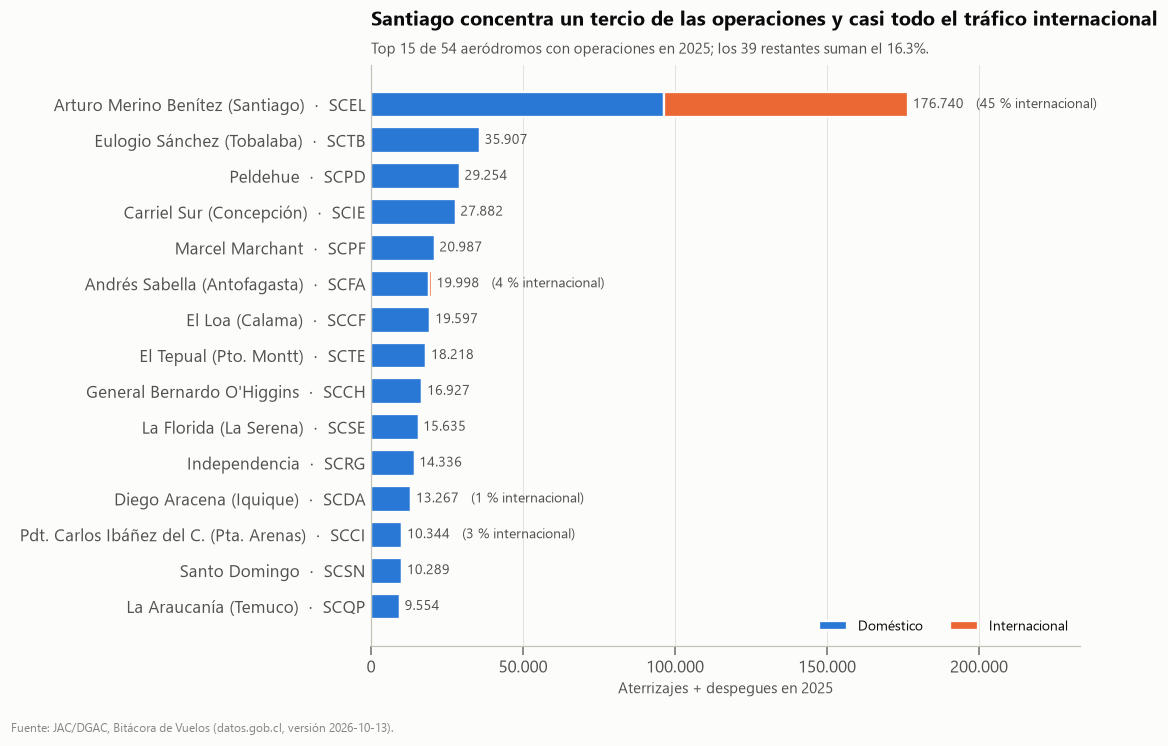

In [53]:
TOP = 15
f1 = agg_aer_ambito.head(TOP).iloc[::-1]
nombres = dim_aer.set_index("oaci")["nombre_corto"]
etiquetas = [f"{nombres.get(c, c)}  ·  {c}" for c in f1.index]
resto = agg_aer_ambito["total"].iloc[TOP:].sum() / agg_aer_ambito["total"].sum()

fig, ax = plt.subplots(figsize=(10, 6.8))
ax.barh(etiquetas, f1["Doméstico"], color=st.COLOR_AMBITO["Doméstico"], height=0.72,
        edgecolor=st.SUPERFICIE, linewidth=1.5, label="Doméstico")
ax.barh(etiquetas, f1["Internacional"], left=f1["Doméstico"], color=st.COLOR_AMBITO["Internacional"],
        height=0.72, edgecolor=st.SUPERFICIE, linewidth=1.5, label="Internacional")
for i, (tot, pint) in enumerate(zip(f1["total"], f1["%_internacional"])):
    txt = st.miles(tot) + (f"   ({pint:.0f} % internacional)" if pint >= 1 else "")
    ax.text(tot + 1500, i, txt, va="center", fontsize=9, color=st.TINTA_2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(st.miles))
ax.set_xlim(0, f1["total"].max() * 1.32)
ax.set_xlabel("Aterrizajes + despegues en 2025")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", ncols=2)
ax.set_title("Santiago concentra un tercio de las operaciones y casi todo el tráfico internacional", pad=26)
ax.text(0, 1.02, f"Top {TOP} de {len(agg_aer_ambito)} aeródromos con operaciones en 2025; los {len(agg_aer_ambito)-TOP} restantes suman el {resto:.1%}.",
        transform=ax.transAxes, fontsize=9.5, color=st.TINTA_2)
st.fuente(ax)
fig.tight_layout(rect=(0, 0.03, 1, 1))
st.guardar(fig, "fig1_mpl_operaciones_aerodromo_2025")
plt.show()

**Lectura (P1).** En 2025 informaron operaciones 54 aeródromos, pero el sistema está muy concentrado: Arturo Merino Benítez (SCEL) suma 176.740 operaciones, el 33,7 % del total y casi 5 veces el segundo (Tobalaba, 35.907). Los cinco primeros suman el 55,5 %. El tráfico internacional es prácticamente exclusivo de Santiago: SCEL concentra el 97,3 % de las operaciones internacionales del país, y en ningún otro aeródromo supera el 5 % de su actividad. Dos de los cinco primeros (Tobalaba y Peldehue) no son aeropuertos comerciales: su volumen viene de aviación general e instrucción, lo que recuerda que **"operaciones" no equivale a "pasajeros"**.

### 9.2 Matplotlib — Figura 2: evolución mensual (P2, H1)

**Decisiones:** la serie doméstica (≈ 35 mil/mes) es 5–6 veces la internacional, así que en un solo panel absoluto la internacional se aplana. En vez de un doble eje (que inventaría una relación entre escalas arbitrarias) se usan **dos paneles con eje x compartido**: (A) valores absolutos mensuales, (B) suma móvil de 12 meses indexada a 2019 = 100, que elimina la estacionalidad y pone ambas series en una escala común.

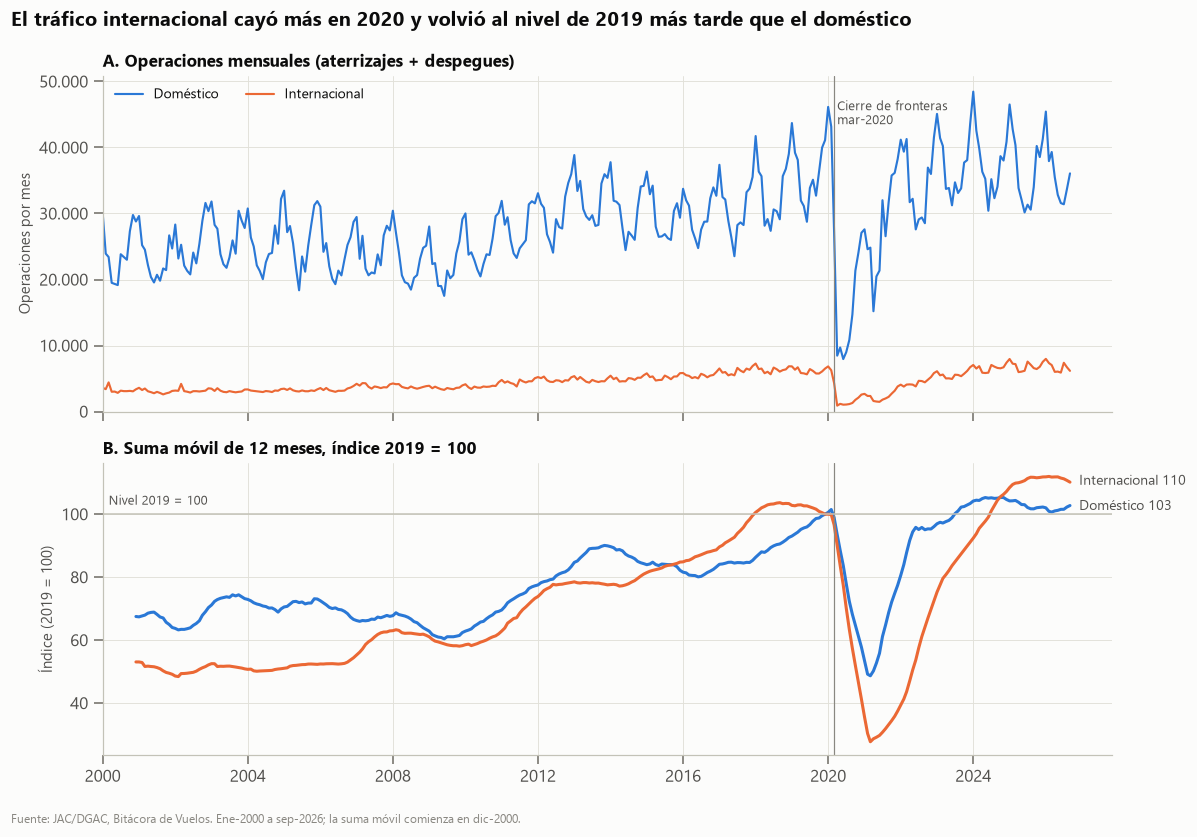

In [54]:
serie = (ops.groupby(["periodo", "ambito"], observed=True).size().unstack("ambito"))
serie.index = serie.index.to_timestamp()
movil = serie.rolling(12).sum()
indice_movil = movil.div(movil.loc["2019-12-01"]).mul(100)

fig, (axa, axb) = plt.subplots(2, 1, figsize=(11, 7.6), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]})
for amb, color in st.COLOR_AMBITO.items():
    axa.plot(serie.index, serie[amb], color=color, lw=1.4, label=amb)
    axb.plot(indice_movil.index, indice_movil[amb], color=color, lw=2, label=amb)

ultimo = indice_movil.iloc[-1]
y_dom, y_int = ultimo["Doméstico"], ultimo["Internacional"]
if abs(y_int - y_dom) < 8:  # separa las etiquetas para que no se superpongan
    centro = (y_int + y_dom) / 2
    y_int, y_dom = (centro + 4, centro - 4) if y_int >= y_dom else (centro - 4, centro + 4)
for amb, y in [("Doméstico", y_dom), ("Internacional", y_int)]:
    axb.annotate(f"{amb} {ultimo[amb]:.0f}", (indice_movil.index[-1], y), xytext=(6, 0),
                 textcoords="offset points", va="center", fontsize=9, color=st.TINTA_2)

for ax in (axa, axb):
    ax.axvline(pd.Timestamp("2020-03-01"), color=st.TINTA_TENUE, lw=0.8)
axa.text(pd.Timestamp("2020-04-01"), axa.get_ylim()[1] * 0.93, "Cierre de fronteras\nmar-2020",
         fontsize=8.5, color=st.TINTA_2, va="top")
axb.axhline(100, color=st.EJE, lw=1)
axb.text(pd.Timestamp("2000-03-01"), 103, "Nivel 2019 = 100", fontsize=8.5, color=st.TINTA_2)

axa.yaxis.set_major_formatter(mticker.FuncFormatter(st.miles))
axa.set_ylabel("Operaciones por mes")
axa.set_ylim(0)
axa.legend(loc="upper left", ncols=2)
axa.set_title("A. Operaciones mensuales (aterrizajes + despegues)", fontsize=11)
axb.set_ylabel("Índice (2019 = 100)")
axb.set_title("B. Suma móvil de 12 meses, índice 2019 = 100", fontsize=11)
axb.set_xlim(serie.index[0], serie.index[-1] + pd.Timedelta(days=420))
fig.suptitle("El tráfico internacional cayó más en 2020 y volvió al nivel de 2019 más tarde que el doméstico",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
st.fuente(axb, "Fuente: JAC/DGAC, Bitácora de Vuelos. Ene-2000 a sep-2026; la suma móvil comienza en dic-2000.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
st.guardar(fig, "fig2_mpl_evolucion_mensual_ambito")
plt.show()

In [55]:
cruce = indice_movil[indice_movil.index >= "2020-03-01"]
for amb in st.COLOR_AMBITO:
    minimo = cruce[amb].idxmin()
    vuelta = cruce[(cruce.index > minimo) & (cruce[amb] >= 100)].index.min()
    print(f"{amb:13s} mínimo {cruce[amb].min():5.1f} en {minimo:%Y-%m} | recupera 100 en {vuelta:%Y-%m} "
          f"({(vuelta.year - 2020) * 12 + vuelta.month - 3} meses desde mar-2020)")
print("\nCaída mensual abr-2020 vs abr-2019:")
print((serie.loc["2020-04-01"] / serie.loc["2019-04-01"] - 1).mul(100).round(1))

Doméstico     mínimo  48.7 en 2021-03 | recupera 100 en 2023-07 (40 meses desde mar-2020)
Internacional mínimo  27.7 en 2021-03 | recupera 100 en 2024-07 (52 meses desde mar-2020)

Caída mensual abr-2020 vs abr-2019:
ambito
Doméstico       -73.50
Internacional   -84.60
dtype: float64


**Lectura (P2 y H1).** Ambas series muestran estacionalidad marcada (peaks en enero y diciembre, valles a mitad de año) y una tendencia creciente desde 2009. En abril de 2020 la actividad doméstica cayó 73,5 % y la internacional 84,6 % respecto de abril de 2019. Con la suma móvil de 12 meses, el doméstico tocó fondo en 48,7 (mar-2021) y recuperó el nivel 2019 en jul-2023 (40 meses después de mar-2020); el internacional tocó fondo en 27,7 y recuperó el nivel recién en jul-2024 (52 meses). Esto es **consistente con H1**. Después, el internacional siguió creciendo (≈ 110) por sobre el doméstico (≈ 103). El gráfico no explica *por qué* (restricciones de frontera, demanda, flota): sólo muestra que las trayectorias difieren.

### 9.3 Seaborn — Figura 3: distribución del tamaño de aeronave (P3)

Se usan las operaciones de 2025 con PMD válido. La escala es **logarítmica** porque el PMD abarca casi cuatro órdenes de magnitud (0,15 t a 450 t): en escala lineal, toda la aviación ligera quedaría comprimida en la primera barra.

Operaciones 2025: 524,301 | con PMD válido: 524,202 (100.0%)


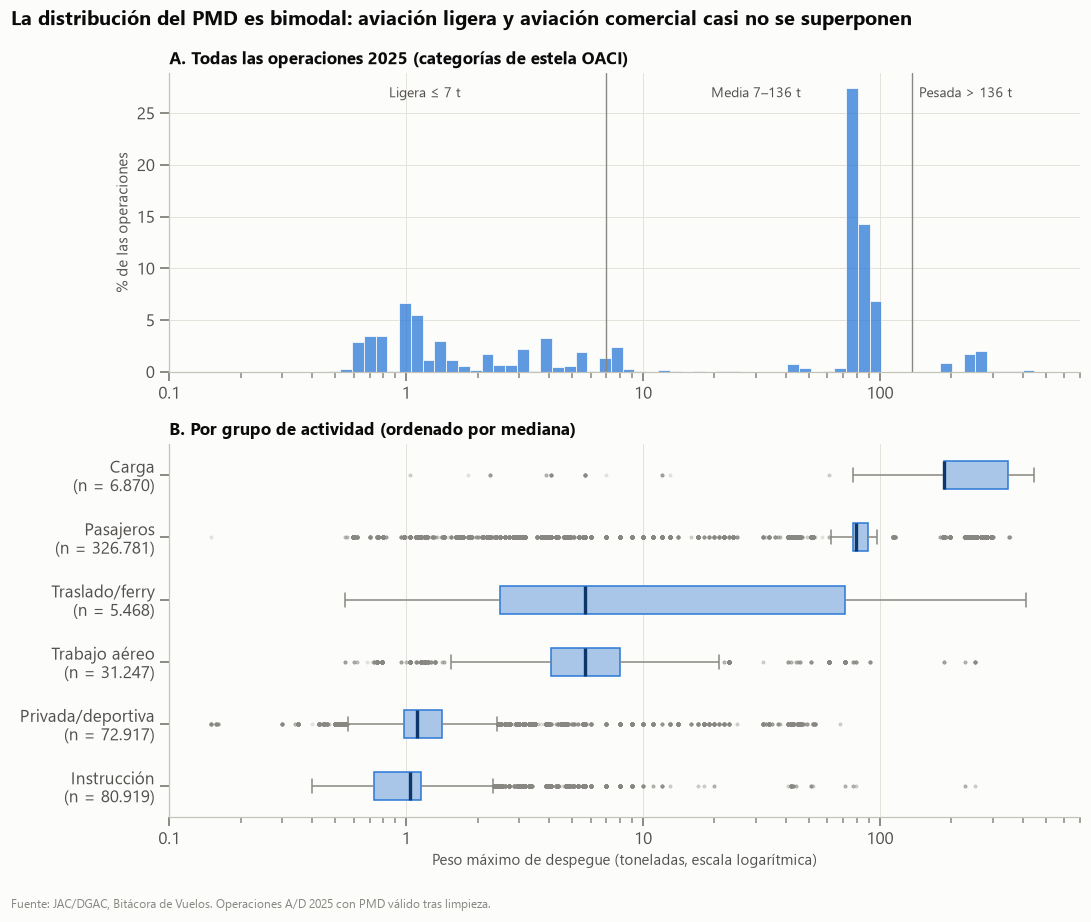

In [56]:
d25 = ops[(ops["anio"] == 2025) & ops["pmd"].notna()]
print(f"Operaciones 2025: {(ops['anio'] == 2025).sum():,} | con PMD válido: {len(d25):,} ({len(d25)/(ops['anio'] == 2025).sum():.1%})")
orden_grupos = (d25.groupby("grupo_actividad", observed=True)["pmd"].median().sort_values(ascending=False))
orden_grupos = [g for g in orden_grupos.index if g not in ("Otros", "Sobrevuelo")]

fig, (axh, axb) = plt.subplots(2, 1, figsize=(10, 8.4), gridspec_kw={"height_ratios": [1, 1.25]})
sns.histplot(data=d25, x="pmd", log_scale=True, bins=70, color=st.AZUL, edgecolor=st.SUPERFICIE,
             linewidth=0.5, ax=axh, stat="percent")
for lim in (7, 136):
    axh.axvline(lim, color=st.TINTA_TENUE, lw=0.9)
for x, txt in [(1.2, "Ligera ≤ 7 t"), (30, "Media 7–136 t"), (230, "Pesada > 136 t")]:
    axh.text(x, axh.get_ylim()[1] * 0.92, txt, ha="center", fontsize=9, color=st.TINTA_2)
axh.set_xlabel("")
axh.set_ylabel("% de las operaciones")
axh.set_title("A. Todas las operaciones 2025 (categorías de estela OACI)", fontsize=11)

sns.boxplot(data=d25, x="pmd", y="grupo_actividad", order=orden_grupos, log_scale=True, color=st.RAMPA_AZUL[1],
            width=0.45, linewidth=1, fliersize=1.5, ax=axb,
            flierprops={"alpha": 0.25, "markeredgecolor": st.TINTA_TENUE},
            medianprops={"color": st.RAMPA_AZUL[-1], "linewidth": 2.2},
            boxprops={"edgecolor": st.AZUL}, whiskerprops={"color": st.TINTA_TENUE},
            capprops={"color": st.TINTA_TENUE})
n_por_grupo = d25["grupo_actividad"].value_counts()
axb.set_yticks(range(len(orden_grupos)), [f"{g}\n(n = {st.miles(n_por_grupo[g])})" for g in orden_grupos])
axb.set_xlabel("Peso máximo de despegue (toneladas, escala logarítmica)")
axb.set_ylabel("")
axb.set_title("B. Por grupo de actividad (ordenado por mediana)", fontsize=11)
for ax in (axh, axb):
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.set_xlim(0.1, 700)
axb.grid(axis="y", visible=False)
fig.suptitle("La distribución del PMD es bimodal: aviación ligera y aviación comercial casi no se superponen",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
st.fuente(axb, "Fuente: JAC/DGAC, Bitácora de Vuelos. Operaciones A/D 2025 con PMD válido tras limpieza.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
st.guardar(fig, "fig3_sns_distribucion_pmd")
plt.show()

Estadísticos para el análisis de distribución:

In [57]:
pmd25 = d25["pmd"]
q1, q3 = pmd25.quantile([.25, .75])
iqr = q3 - q1
desc = pd.Series({
    "media": pmd25.mean(), "mediana": pmd25.median(), "desv_estándar": pmd25.std(),
    "asimetría (escala lineal)": pmd25.skew(), "asimetría (log10)": np.log10(pmd25).skew(),
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "% sobre Q3 + 1,5·IQR": (pmd25 > q3 + 1.5 * iqr).mean() * 100,
})
print(desc.round(2))
print("\nCategoría de estela (%):")
print(d25["categoria_estela"].value_counts(normalize=True).mul(100).round(1))
d25.groupby("grupo_actividad", observed=True)["pmd"].describe().loc[orden_grupos].round(2)

media                       55.03
mediana                     77.00
desv_estándar               61.11
asimetría (escala lineal)    1.90
asimetría (log10)           -0.35
Q1                           1.41
Q3                          89.00
IQR                         87.59
% sobre Q3 + 1,5·IQR         4.22
dtype: float64

Categoría de estela (%):
categoria_estela
Media (7–136 t)   53.50
Ligera (≤7 t)     41.40
Pesada (>136 t)    5.10
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
grupo_actividad,,,,,,,,
Carga,"6,870.00",252.88,108.28,1.04,187.00,187.00,348.00,448.00
Pasajeros,"326,781.00",81.11,51.06,0.15,77.00,79.00,89.00,353.00
Traslado/ferry,"5,468.00",30.41,46.29,0.55,2.50,5.68,71.00,413.00
Trabajo aéreo,"31,247.00",7.00,10.48,0.55,4.09,5.68,8.00,253.00
Privada/deportiva,"72,917.00",1.69,3.67,0.15,0.98,1.11,1.41,68.00
Instrucción,"80,919.00",1.18,2.61,0.40,0.73,1.04,1.16,253.00


**Análisis de distribución (P3).**

- **¿Dónde se concentra?** En dos zonas separadas: aviación ligera (≈ 0,6–2 t: instrucción y vuelo privado) y aviación comercial de fuselaje angosto (≈ 70–90 t, A320/A321/B737), que por sí sola reúne cerca de la mitad de las operaciones. Hay un tercer grupo pequeño de aviones de fuselaje ancho (> 136 t, 5,1 %). La mediana global (77 t) cae en el segundo grupo, mientras que la media (55 t) cae en un valle casi vacío: **en una distribución bimodal la media no representa a ninguna operación típica**.
- **¿Asimetría?** En escala lineal la asimetría es positiva (1,90: cola larga hacia aviones pesados). En escala logarítmica es levemente negativa (−0,35). La forma depende de la escala; lo relevante es la bimodalidad.
- **¿Dispersión?** Muy alta entre grupos (de 1 t a 187 t de mediana) y muy baja dentro de pasajeros (IQR 77–89 t). Traslado/ferry es el grupo más heterogéneo: mezcla avionetas y aviones comerciales vacíos.
- **¿Valores extremos?** Sí: el 4,2 % de las operaciones supera Q3 + 1,5·IQR, pero **son aviones reales** (fuselaje ancho de pasajeros y carga), no errores: los errores evidentes se trataron en §6. Dentro de los grupos aparecen operaciones atípicas plausibles (aeronaves pequeñas en servicios de pasajeros tipo taxi aéreo; aviones comerciales en instrucción).
- **Implicación:** el PMD **no debe resumirse con la media** ni analizarse en escala lineal; conviene tratarlo por categorías (estela OACI) o por grupo. En 2025 el 99,98 % de las operaciones tiene PMD válido: los problemas de calidad de PMD son sobre todo históricos.

### 9.4 Seaborn — Figura 4: segmentación del perfil horario (P3)

Cada fila se normaliza por su propio total (porcentaje de las operaciones del grupo en cada hora). Sin normalizar, Pasajeros (≈ 330 mil operaciones) dominaría la escala de color y los demás grupos se verían vacíos; la pregunta es por la **forma** del día, no por el volumen.

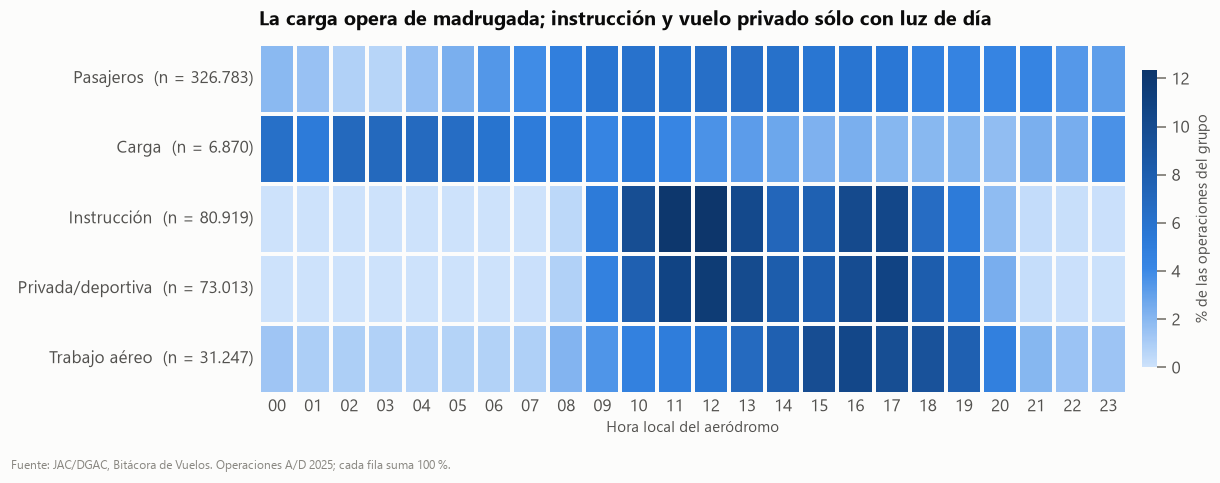

In [58]:
fig, ax = plt.subplots(figsize=(12, 4.4))
n_grupo = horario.sum(axis=1)
sns.heatmap(horario_pct, cmap=st.CMAP_SECUENCIAL, vmin=0, linewidths=1.5, linecolor=st.SUPERFICIE,
            cbar_kws={"label": "% de las operaciones del grupo", "shrink": 0.85, "pad": 0.015}, ax=ax)
ax.set_yticklabels([f"{g}  (n = {st.miles(n_grupo[g])})" for g in horario_pct.index], rotation=0)
ax.set_xticklabels([f"{h:02d}" for h in horario_pct.columns], rotation=0)
ax.set_xlabel("Hora local del aeródromo")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.set_title("La carga opera de madrugada; instrucción y vuelo privado sólo con luz de día", pad=12)
st.fuente(ax, "Fuente: JAC/DGAC, Bitácora de Vuelos. Operaciones A/D 2025; cada fila suma 100 %.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
st.guardar(fig, "fig4_sns_perfil_horario_actividad")
plt.show()

In [59]:
diurno = horario_pct.loc[:, 8:19].sum(axis=1)
nocturno = horario_pct.loc[:, [0, 1, 2, 3, 4, 5]].sum(axis=1)
pd.DataFrame({"% entre 08 y 19 h": diurno, "% entre 00 y 05 h": nocturno, "hora pico": horario_pct.idxmax(axis=1)}).round(1)

,% entre 08 y 19 h,% entre 00 y 05 h,hora pico
grupo_actividad,,,
Pasajeros,68.10,9.10,13
Carga,39.70,39.00,2
Instrucción,97.60,0.00,12
Privada/deportiva,96.80,0.10,12
Trabajo aéreo,82.90,5.60,16


**Lectura (P3, segmentación).** Los grupos se separan claramente por horario: instrucción y vuelo privado concentran el 97 % de su actividad entre las 08 y las 19 h, con un pico al mediodía. La carga tiene el patrón opuesto: el 39 % de sus operaciones ocurre entre las 00 y las 05 h, con pico a las 02 h. Los pasajeros cubren casi todo el día (68 % entre 08 y 19 h, pero 9 % en la madrugada). El trabajo aéreo se desplaza hacia la tarde (pico a las 16 h). El patrón es consistente con restricciones operacionales conocidas (vuelo visual de día, carga de largo alcance de noche), pero los datos no registran esa causa.

### 9.5 Visualización multidimensional — Figura 5 (H1 por tipo de actividad)

¿La recuperación más lenta del tráfico internacional se repite en todos los tipos de actividad, o depende del grupo? Se combinan **cuatro variables**: año, número de operaciones, ámbito y grupo de actividad (cuatro grupos con tráfico internacional suficiente para comparar: Instrucción se excluye porque tiene entre 0 y 15 operaciones internacionales por año, y un índice sobre esa base no significa nada).

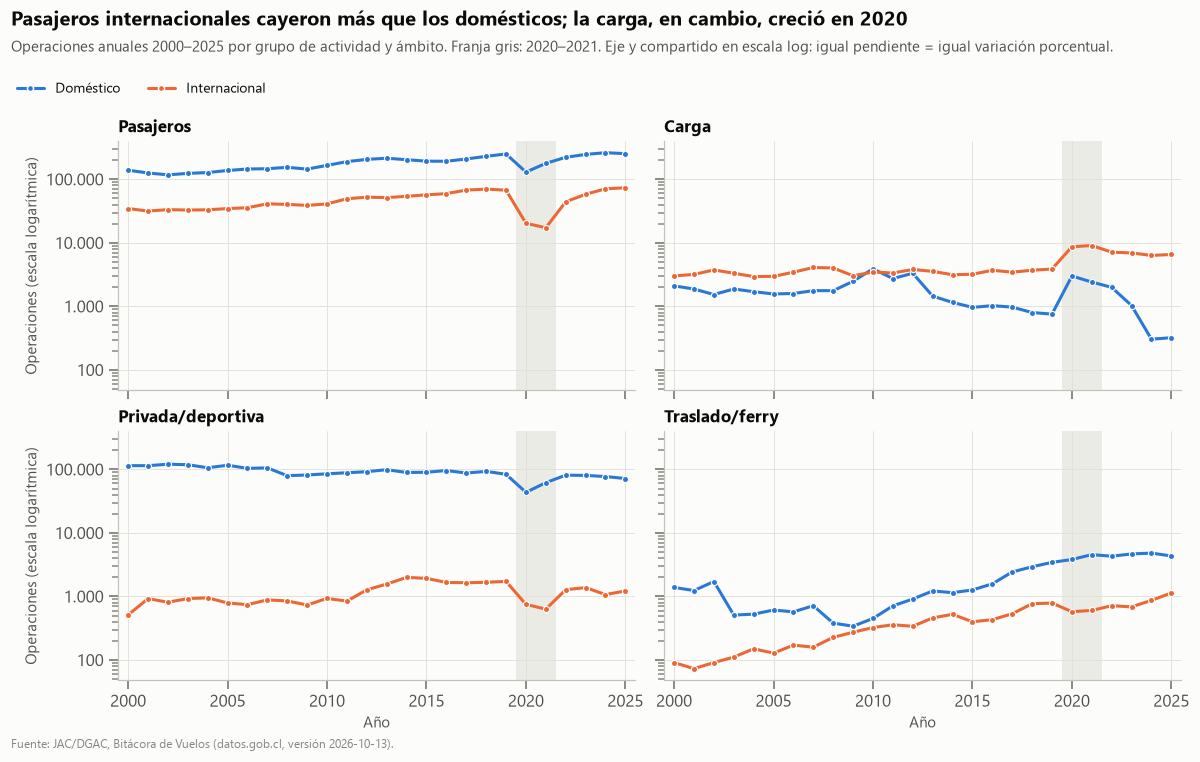

In [60]:
GRUPOS_F5 = ["Pasajeros", "Carga", "Privada/deportiva", "Traslado/ferry"]
f5 = agg_anual.query("grupo_actividad in @GRUPOS_F5").copy()
f5["grupo_actividad"] = pd.Categorical(f5["grupo_actividad"].astype(str), categories=GRUPOS_F5)

g = sns.relplot(data=f5, x="anio", y="n_operaciones", hue="ambito", col="grupo_actividad", col_wrap=2,
                kind="line", palette=st.COLOR_AMBITO, hue_order=list(st.COLOR_AMBITO), linewidth=2,
                marker="o", markersize=4, markeredgecolor=st.SUPERFICIE, height=3.4, aspect=1.6,
                facet_kws={"sharey": True, "sharex": True})
g.set(yscale="log", xlim=(1999.5, 2025.5))
for ax in g.axes.flat:
    ax.axvspan(2019.5, 2021.5, color=st.GRILLA, alpha=0.6, lw=0, zorder=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(st.miles))
    ax.grid(True, which="major")
g.set_titles(col_template="{col_name}", size=11, weight="bold")
g.set_axis_labels("Año", "Operaciones (escala logarítmica)")
g.legend.set_title("")
sns.move_legend(g, "upper left", bbox_to_anchor=(0.005, 0.915), ncols=2, frameon=False)
g.figure.suptitle("Pasajeros internacionales cayeron más que los domésticos; la carga, en cambio, creció en 2020",
                  x=0.01, y=0.995, ha="left", fontsize=13, fontweight="bold")
g.figure.text(0.01, 0.94, "Operaciones anuales 2000–2025 por grupo de actividad y ámbito. Franja gris: 2020–2021. "
              "Eje y compartido en escala log: igual pendiente = igual variación porcentual.",
              fontsize=9.5, color=st.TINTA_2)
g.figure.subplots_adjust(top=0.82, bottom=0.1)
st.fuente(g.axes.flat[-1])
st.guardar(g.figure, "fig5_sns_multidimensional_recuperacion")
plt.show()

In [61]:
tabla_h1 = (f5.query("anio in [2019, 2020, 2021, 2022, 2023, 2024, 2025]")
              .pivot_table(index=["grupo_actividad", "ambito"], columns="anio", values="indice_2019", observed=True)
              .round(0))
tabla_h1

anio                              2019   2020   2021   2022   2023   2024   2025
grupo_actividad   ambito                                                        
Pasajeros         Doméstico     100.00  52.00  71.00  88.00  98.00 105.00 101.00
                  Internacional 100.00  30.00  26.00  66.00  86.00 105.00 109.00
Carga             Doméstico     100.00 398.00 320.00 264.00 136.00  40.00  43.00
                  Internacional 100.00 224.00 234.00 184.00 179.00 164.00 169.00
Privada/deportiva Doméstico     100.00  52.00  74.00  97.00  96.00  92.00  86.00
                  Internacional 100.00  43.00  37.00  74.00  80.00  62.00  71.00
Traslado/ferry    Doméstico     100.00 111.00 132.00 125.00 136.00 140.00 126.00
                  Internacional 100.00  73.00  76.00  91.00  87.00 110.00 144.00

**Lectura (H1 por actividad).** La respuesta depende del grupo:

- **Pasajeros** (57 % de las operaciones): H1 se cumple. En 2021 el internacional estaba en 26 (índice 2019 = 100) y el doméstico en 71; ambos superan 100 recién en 2024, y en 2025 el internacional (109) quedó por sobre el doméstico (101).
- **Privada/deportiva:** ambos cayeron, el internacional más (37 vs 74 en 2021), y **ninguno ha vuelto** al nivel 2019 (71 y 86 en 2025).
- **Carga:** H1 **no** se cumple: la carga creció en 2020 (doméstica ×4, internacional ×2,2) y la internacional se mantiene en 169. La carga doméstica, en cambio, cayó después a 40, bajo su nivel previo.
- **Traslado/ferry:** el doméstico sigue la tendencia creciente previa; el internacional cayó 27 % en 2020 y en 2025 llega a 144.

Por lo tanto, H1 describe bien el tráfico de pasajeros (que domina el total, por eso aparece en la Figura 2), pero no es una regla general para todos los tipos de actividad. El aumento de carga en 2020 coincide en el tiempo con la caída de pasajeros; estos datos no permiten afirmar que una cosa causó la otra.

**Canales visuales**

| Variable | Canal | Justificación |
|---|---|---|
| Año (temporal, ordinal) | Posición en x | La posición es el canal más preciso y el tiempo se lee de izquierda a derecha |
| Operaciones (medida) | Posición en y, escala log | Precisión máxima para la medida; la escala log permite comparar *ritmos* de caída y recuperación entre series de 10 a 300.000 operaciones en el mismo eje |
| Ámbito (nominal, 2 niveles) | Color (azul/naranja) | Sólo dos categorías: el tono las separa al instante y se mantiene la misma asignación que en las Figuras 1 y 2. Los marcadores redondos y la leyenda evitan depender sólo del color |
| Grupo de actividad (nominal, 4 niveles) | Faceta (*small multiples*) | Superponer 8 líneas en un panel sería ilegible; las facetas con ejes compartidos permiten comparar entre paneles sin re-leer escalas |

**¿Qué pasaría con una dimensión adicional?** Por ejemplo, agregar el aeródromo (54 niveles) como forma o grosor de línea: la forma sólo distingue bien ≈ 5 categorías y el color ya está ocupado, así que terminaríamos con decenas de líneas superpuestas por panel. Agregarlo como segunda faceta (filas × columnas) produciría 4 × 54 paneles diminutos. En ambos casos aumenta la carga cognitiva (el lector debe recordar más codificaciones a la vez) y se pierde la comparación principal (doméstico vs internacional). Si esa dimensión fuera necesaria, lo correcto sería **filtrar** (p. ej. sólo SCEL) o **hacer otro gráfico**, no agregar un canal.

## 10. Benchmark visual

**Pregunta (P2):** ¿existe un patrón estacional estable en las operaciones mensuales, y cómo lo alteró 2020?

Se resuelve con dos visualizaciones distintas a partir de la misma tabla (`pivot_anio_mes`, 2000–2025).

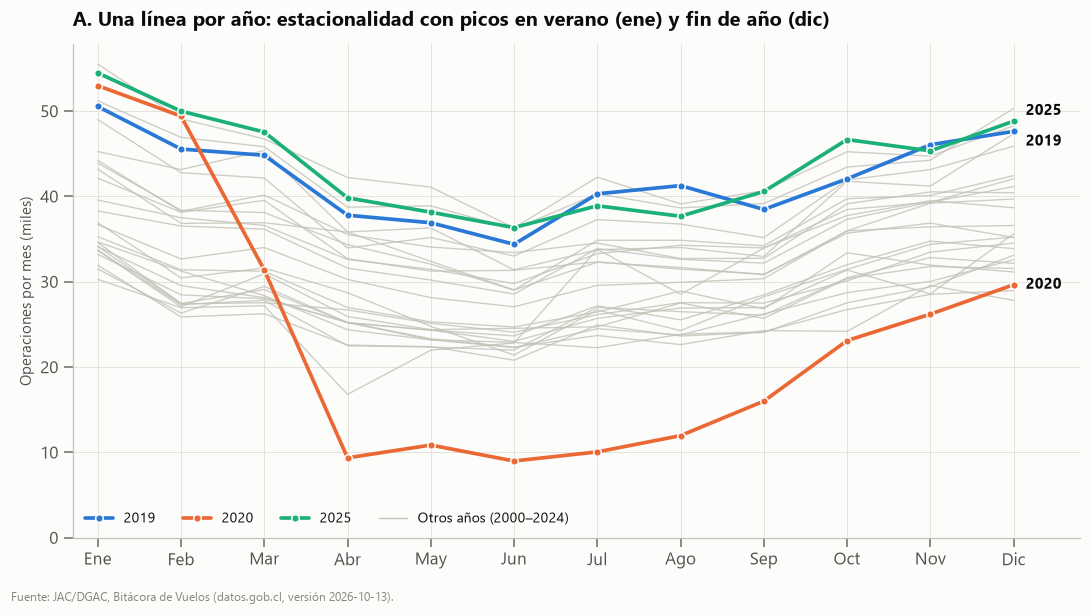

In [62]:
pivot_miles = pivot_anio_mes / 1000
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
DESTACADOS = {2019: st.AZUL, 2020: st.NARANJA, 2025: st.AQUA}

fig, ax = plt.subplots(figsize=(10, 5.6))
for anio, fila in pivot_miles.iterrows():
    if anio not in DESTACADOS:
        ax.plot(range(1, 13), fila.values, color=st.GRIS_CONTEXTO, lw=0.9, alpha=0.8, zorder=1)
y_etiqueta = {a: pivot_miles.loc[a, 12] for a in DESTACADOS}
a_bajo, a_alto = sorted([2019, 2025], key=y_etiqueta.get)
if y_etiqueta[a_alto] - y_etiqueta[a_bajo] < 2.5:  # separa etiquetas cercanas
    y_etiqueta[a_alto] += 1.2
    y_etiqueta[a_bajo] -= 1.2
for anio, color in DESTACADOS.items():
    fila = pivot_miles.loc[anio]
    ax.plot(range(1, 13), fila.values, color=color, lw=2.4, marker="o", markersize=5,
            markeredgecolor=st.SUPERFICIE, zorder=3, label=str(anio))
    ax.annotate(str(anio), (12, y_etiqueta[anio]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=10, color=st.TINTA, fontweight="bold")
ax.plot([], [], color=st.GRIS_CONTEXTO, lw=0.9, label="Otros años (2000–2024)")
ax.set_xticks(range(1, 13), MESES)
ax.set_xlim(0.7, 12.8)
ax.set_ylim(0)
ax.set_ylabel("Operaciones por mes (miles)")
ax.legend(loc="lower left", ncols=4)
ax.set_title("A. Una línea por año: estacionalidad con picos en verano (ene) y fin de año (dic)", pad=12)
st.fuente(ax)
fig.tight_layout(rect=(0, 0.03, 1, 1))
st.guardar(fig, "fig6a_benchmark_lineas_por_anio")
plt.show()

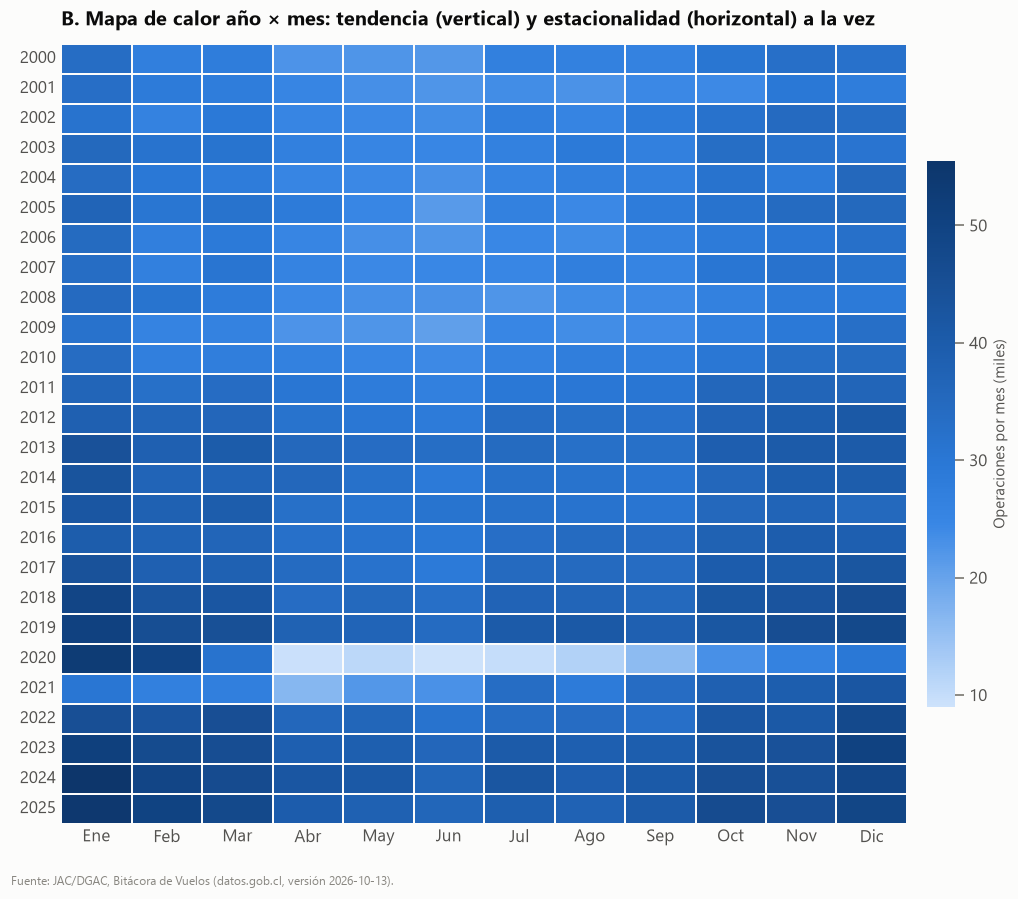

In [63]:
fig, ax = plt.subplots(figsize=(10, 8.2))
sns.heatmap(pivot_miles, cmap=st.CMAP_SECUENCIAL, linewidths=1, linecolor=st.SUPERFICIE,
            cbar_kws={"label": "Operaciones por mes (miles)", "shrink": 0.7, "pad": 0.02},
            xticklabels=MESES, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_title("B. Mapa de calor año × mes: tendencia (vertical) y estacionalidad (horizontal) a la vez", pad=12)
st.fuente(ax)
fig.tight_layout(rect=(0, 0.03, 1, 1))
st.guardar(fig, "fig6b_benchmark_mapa_calor")
plt.show()

Índice estacional (participación de cada mes en el año), excluyendo 2020–2021 por ser años anómalos, y su estabilidad entre años:

In [64]:
part = pivot_anio_mes.div(pivot_anio_mes.sum(axis=1), axis=0) * 100
normales = part.drop(index=[2020, 2021])
estacionalidad = pd.DataFrame({"% medio del año": normales.mean(), "desv. estándar entre años": normales.std(),
                               "% en 2020": part.loc[2020]}).round(2)
estacionalidad.index = MESES
estacionalidad

,% medio del año,desv. estándar entre años,% en 2020
Ene,10.03,0.44,18.92
Feb,8.74,0.50,17.65
Mar,8.81,0.35,11.21
Abr,7.66,0.34,3.34
May,7.32,0.24,3.88
Jun,6.91,0.30,3.21
Jul,7.68,0.29,3.59
Ago,7.63,0.36,4.27
Sep,7.69,0.28,5.72
Oct,8.81,0.38,8.25


**Lectura.** El patrón estacional es muy estable: enero concentra en promedio el 10,0 % de las operaciones del año y junio el 6,9 %, con una desviación entre años de apenas 0,2–0,5 puntos. En 2020 el patrón se rompió: enero y febrero representaron el 19 % y 18 % del año, porque el resto del año colapsó.

### 10.1 Comparación

| Criterio | A. Líneas por año (resaltado) | B. Mapa de calor año × mes |
|---|---|---|
| **Claridad** | Alta para la *forma* estacional y para 2020; el resaltado guía la lectura | Media: hay que aprender a leer dos ejes temporales y la escala de color |
| **Precisión** | Alta: los valores se leen en el eje y (posición) | Baja: el color es un canal impreciso; distinguir 38 de 42 mil es casi imposible |
| **Comparabilidad** | Muy buena entre meses de un mismo año y entre 3 años destacados; mala entre los 23 años grises | Muy buena entre años (tendencia vertical) y entre meses (franjas horizontales) a la vez |
| **Densidad informativa** | 312 valores, pero sólo 36 legibles; el resto es contexto | 312 valores, todos visibles, sin superposición |
| **Carga cognitiva** | Baja si se destacan ≤ 3 años; muy alta sin resaltado (26 líneas superpuestas) | Moderada y constante |
| **Utilidad** | Responder "¿cuál es el patrón estacional y cómo se desvió 2020?" | Explorar: ver tendencia, estacionalidad y anomalías (2020–2021) al mismo tiempo |

**¿Cuál usar?** Para **esta** pregunta (¿existe un patrón estacional estable y cómo lo alteró 2020?), la **A**: la estacionalidad es una *forma* (subidas y bajadas dentro del año) y la forma se lee mejor como posición sobre un eje que como color, y la anomalía de 2020 aparece de inmediato porque está resaltada. El mapa de calor es mejor herramienta exploratoria y para una audiencia analítica que necesite ver los 26 años a la vez, pero la tendencia creciente domina la escala de color y hace que la estacionalidad (± 15 % dentro de un año) se vea débil. Si hubiera que usar B para esta pregunta, convendría normalizar cada fila (participación del mes en su año), sacrificando la tendencia.

## 11. Validación

Las dos visualizaciones definitivas más importantes son la **Figura 2** (evolución y H1) y la **Figura 1** (concentración). Antes de auditarlas en lo cualitativo se verifica por código que los datos graficados son íntegros: que no falten meses, que los totales cuadren con la tabla de origen y que coincidan con el resumen oficial publicado por la JAC (fuente independiente del cálculo).

In [65]:
# Figura 2: serie mensual completa y conciliada con el resumen oficial
meses_esperados = pd.period_range("2000-01", "2026-09", freq="M").to_timestamp()
assert serie.index.equals(meses_esperados), "Faltan o sobran meses en la serie"
assert int(serie.sum().sum()) == len(ops), "La serie no suma el total de operaciones"

oficial = resumen.assign(ambito=resumen["internacional_domestico"].map({"D": "Doméstico", "I": "Internacional"}),
                         periodo=pd.to_datetime(resumen["mes_id"].astype(str), format="%Y%m"))
oficial = oficial.pivot_table(index="periodo", columns="ambito", values="cnt_operaciones", aggfunc="sum")
dif = (serie - oficial).loc[:"2026-08-01"]
print("Figura 2 vs resumen oficial (ene-2000 a ago-2026):")
print("  diferencia máxima mensual (operaciones):", dif.abs().max().to_dict())
print(f"  diferencia relativa máxima: {(dif.abs() / oficial.loc[dif.index]).max().max():.3%}")
print("  meses con diferencia ≠ 0:", int((dif != 0).any(axis=1).sum()), "— todas con la figura por debajo del oficial")
assert (dif <= 0).all().all(), "La figura nunca debería superar al resumen oficial"
print(f"  operaciones de diferencia en total: {int(-dif.sum().sum()):,} "
      f"(duplicados A/D eliminados + registro 't'; ver log de limpieza: {int(log_limpieza.iloc[8, 1]):,} duplicados en total, incluidos sobrevuelos)")

# Figura 1: totales por aeródromo
assert (f1["Doméstico"] + f1["Internacional"] == f1["total"]).all()
of25 = resumen[resumen["mes_id"] // 100 == 2025].groupby("aeropuerto_oaci")["cnt_operaciones"].sum()
comp_f1 = pd.DataFrame({"figura": f1["total"], "oficial": of25.reindex(f1.index)})
comp_f1["diferencia"] = comp_f1["figura"] - comp_f1["oficial"]
print("\nFigura 1 vs resumen oficial 2025 — diferencia máxima:", int(comp_f1["diferencia"].abs().max()))

Figura 2 vs resumen oficial (ene-2000 a ago-2026):
  diferencia máxima mensual (operaciones): {'Doméstico': 291, 'Internacional': 0}
  diferencia relativa máxima: 1.197%
  meses con diferencia ≠ 0: 67 — todas con la figura por debajo del oficial
  operaciones de diferencia en total: 1,184 (duplicados A/D eliminados + registro 't'; ver log de limpieza: 1,186 duplicados en total, incluidos sobrevuelos)

Figura 1 vs resumen oficial 2025 — diferencia máxima: 0


La Figura 1 reproduce exactamente el resumen oficial de 2025. La Figura 2 queda siempre igual o por debajo del oficial, con una diferencia máxima de 1,2 % en un mes de 2004: el resumen oficial incluye los duplicados (también los que sólo se distinguen por espacios o fracciones de segundo) y el registro `'t'`, que aquí se eliminaron. Auditoría cualitativa:

| Criterio | Figura 2 — Evolución mensual por ámbito | Figura 1 — Operaciones por aeródromo 2025 |
|---|---|---|
| **Propósito** | Mostrar la evolución 2000–2026 y comparar la caída y recuperación doméstica vs internacional (P2, H1) | Mostrar la concentración de la actividad y el peso internacional por aeródromo (P1) |
| **Audiencia** | Analistas y tomadores de decisión del sector; requiere leer un índice | Público general y directivos; lectura inmediata |
| **Selección de datos** | Sólo A y D (sin sobrevuelos), ene-2000 a sep-2026; 2026 incluido porque es serie mensual (no compara años parciales) | Sólo 2025 (último año completo), top 15 de 54; el resto (16,3 %) se declara en el subtítulo |
| **Agregación** | Mensual (panel A) y suma móvil 12 meses (panel B): el B elimina la estacionalidad pero retrasa los cambios (un quiebre se ve "suavizado" a lo largo de 12 meses) | Anual por aeródromo × ámbito: oculta estacionalidad y tipo de actividad |
| **Escalas** | A: lineal desde 0. B: índice con base 2019 = 100. La elección de base cambia el relato: con base 2000 ambas series "crecen"; 2019 se eligió porque es el último año prepandemia | Lineal desde 0, obligatorio en barras; separadores de miles en formato chileno |
| **Color** | Azul/naranja de la paleta validada para daltonismo; se mantiene el mismo significado en todo el proyecto; etiquetas directas al final de cada línea | Mismos colores; la identidad no depende sólo del color (leyenda + texto "% internacional") |
| **Dimensiones** | Tiempo (x) + ámbito (color): 2, adecuado | Aeródromo (y) + ámbito (color): 2, adecuado |
| **Legibilidad** | Título enuncia el hallazgo; anotación de mar-2020; sin doble eje | Etiquetas largas en horizontal sin rotar; totales rotulados |
| **Integridad** | Verificada por código contra el resumen oficial (arriba) | Verificada por código contra el resumen oficial (arriba) |
| **Posibles sesgos** | La cobertura excluye aeródromos no DGAC y vuelos militares: la "actividad aérea de Chile" está subestimada en forma no aleatoria | "Operaciones" mezcla vuelos de escuela y de aerolíneas: Tobalaba aparece 2.º aunque casi no mueve pasajeros |
| **Interpretación errónea posible** | Leer el panel B como "en 2025 hay 10 % más vuelos internacionales que en 2019" es correcto; leerlo como "10 % más pasajeros internacionales" no lo es | Leer la barra como importancia económica o de pasajeros del aeródromo |
| **Limitaciones** | No muestra causas; no separa actividades (lo hace la Fig. 5) | Un solo año; no muestra tendencia por aeródromo |

## 12. Interpretación

**HALLAZGO 1 — El sistema aeroportuario está concentrado en Santiago, y el tráfico internacional casi totalmente.**
- **Datos utilizados:** operaciones A/D de 2025 por aeródromo y ámbito (`agg_aer_ambito`).
- **Evidencia:** SCEL = 176.740 operaciones (33,7 % del total, 4,9 veces el segundo); concentra el 97,3 % de las operaciones internacionales; los 5 primeros aeródromos suman el 55,5 %.
- **Visualización:** Figura 1.
- **Interpretación:** la conectividad internacional del país depende de un solo aeropuerto. Esta concentración es un hecho estructural de los datos; sus causas (infraestructura, demanda, regulación) no se observan en este dataset.
- **Posible utilidad:** evaluación de riesgo operacional (un cierre de SCEL afecta prácticamente todo el tráfico internacional) y discusión de políticas de conectividad regional.
- **Limitación:** se cuentan operaciones, no pasajeros ni carga; los aeródromos de aviación general aparecen sobrerrepresentados respecto de su importancia en pasajeros.

**HALLAZGO 2 — Tras 2020, el tráfico internacional de pasajeros tardó más en recuperarse que el doméstico.**
- **Datos utilizados:** serie mensual 2000–2026 por ámbito; agregación anual por ámbito × actividad con índice 2019 = 100.
- **Evidencia:** caída abr-2020 vs abr-2019: −73,5 % doméstico y −84,6 % internacional. Suma móvil 12 meses: el doméstico recuperó el nivel 2019 en jul-2023 (40 meses) y el internacional en jul-2024 (52 meses). En pasajeros, el índice 2021 fue 71 (doméstico) vs 26 (internacional).
- **Visualización:** Figuras 2 y 5.
- **Interpretación:** los datos son consistentes con H1 para pasajeros; no lo son para carga (que creció) ni se generaliza a todas las actividades. La diferencia temporal coincide con el periodo de restricciones de frontera, pero **este dataset no contiene variables que permitan atribuir la causa**.
- **Posible utilidad:** dimensionar los tiempos de recuperación ante shocks futuros en planes de contingencia aeroportuaria.
- **Limitación:** operaciones ≠ pasajeros (los aviones pueden haber volado con menor ocupación); la suma móvil desplaza en el tiempo la fecha de "recuperación".

**HALLAZGO 3 — Los tipos de actividad son segmentos operacionales distintos: difieren en tamaño de aeronave y en horario.**
- **Datos utilizados:** operaciones 2025 con PMD válido (524.202) y perfil horario normalizado por grupo.
- **Evidencia:** PMD mediano de 187 t en carga, 79 t en pasajeros, 1,1 t en privada y 1,0 t en instrucción. Instrucción y privada concentran el 97 % de su actividad entre 08 y 19 h; la carga tiene el 39 % entre 00 y 05 h (pico a las 02 h). El 74 % de la instrucción son vuelos locales.
- **Visualización:** Figuras 3 y 4.
- **Interpretación:** "operaciones" agrupa realidades muy distintas; cualquier análisis de capacidad o de impacto debería segmentar por actividad. La distribución bimodal del PMD hace que su media (55 t) no describa ninguna operación típica.
- **Posible utilidad:** planificación de turnos y servicios aeroportuarios nocturnos (carga), y de espacio aéreo diurno en aeródromos con escuelas de vuelo.
- **Limitación:** el PMD es un atributo del tipo de avión, no el peso real del vuelo; los horarios son de 2025 y podrían variar en otros años.

**De dato a acción (ejemplo con el Hallazgo 2):**
DATO: 10,7 M de operaciones registradas → EVIDENCIA: el índice internacional de pasajeros se mantuvo bajo 70 hasta 2022 mientras el doméstico superaba 85 → INTERPRETACIÓN: la recuperación fue asimétrica entre ámbitos (sin inferir la causa) → POSIBLE ACCIÓN: al planificar contingencias, modelar escenarios de recuperación separados para tráfico doméstico e internacional en lugar de uno agregado.

## 13. Ética profesional, limitaciones y conclusiones

### 13.1 Decisión analizada: escala logarítmica compartida en la Figura 5

- **¿Qué decisión tomé?** Mostrar las operaciones anuales en escala logarítmica, con el eje y compartido entre facetas.
- **¿Qué evidencia la sustentó?** Las series van de ≈ 100 a ≈ 250.000 operaciones anuales. En escala lineal compartida, carga, traslado y todo el tráfico internacional de privada quedarían aplastados en el piso del eje; la pregunta (H1) es sobre *ritmos relativos* de caída y recuperación, que en escala log se leen como pendientes comparables.
- **¿Qué otra decisión pude adoptar?** (a) Escala lineal con ejes independientes por faceta; (b) índice 2019 = 100 en escala lineal; (c) escala lineal compartida.
- **¿Cómo afecta al resultado?** En escala log una caída de 74 % (pasajeros internacionales 2019→2021) se ve como un descenso moderado, y las diferencias de volumen entre grupos se comprimen: la carga internacional (≈ 6.500) parece "cercana" a los pasajeros internacionales (≈ 73.000), aunque es 11 veces menor.
- **¿Puede modificar la percepción del lector?** Sí. Un lector no habituado a escalas log puede subestimar la magnitud de los cambios o la diferencia de tamaño entre grupos. Con ejes independientes (opción a), en cambio, el lector podría creer que todos los grupos tienen volumen similar.
- **¿Qué debería declarar?** Que el eje es logarítmico (está en la etiqueta del eje y en el subtítulo, con la regla "igual pendiente = igual variación porcentual"), y acompañar la figura con la tabla de índices (`tabla_h1`) y los valores absolutos de 2025 para que la magnitud no dependa de la lectura visual.

Otras decisiones con implicancias éticas, declaradas en este notebook: el umbral ×3 de PMD (§5.8), la eliminación de duplicados que hace que nuestras cifras difieran levemente de las oficiales (§6.1), la exclusión de Instrucción en la Figura 5 (§9.5) y el corte del top 15 en la Figura 1 (declarado en el subtítulo).

### 13.2 Limitaciones

1. **Cobertura:** sólo aeródromos administrados por la DGAC; se excluyen vuelos militares y policiales. No es "toda la aviación de Chile".
2. **Operaciones ≠ pasajeros ni carga:** el dataset no tiene pasajeros, toneladas ni ocupación.
3. **Sin identificador de vuelo:** no se pueden reconstruir rutas completas ni emparejar despegues con aterrizajes de forma confiable.
4. **PMD:** 3,6 % de las operaciones sin valor válido tras la limpieza (mayormente en años antiguos); el umbral de limpieza es una decisión del analista.
5. **Periodo:** 2026 parcial (hasta sep); los registros del último día pueden corregirse en versiones futuras de la fuente; los resultados corresponden a la versión del 13-10-2026.
6. **Asociación, no causalidad:** los patrones temporales (2020) coinciden con eventos conocidos, pero el dataset no contiene variables para atribuir causas.

### 13.3 Conclusiones

Respondiendo la pregunta principal: la actividad de aterrizajes y despegues informada por la DGAC creció de ≈ 330 mil operaciones anuales (2000) a ≈ 524 mil (2025), con una **estacionalidad muy estable** (peak en enero, valle en junio) y una **fuerte concentración** en Santiago, que concentra un tercio de las operaciones y casi todo el tráfico internacional (P1, P2). El shock de 2020 reveló **trayectorias distintas**: el tráfico internacional de pasajeros cayó más y tardó un año más en recuperar el nivel 2019 que el doméstico, consistente con H1; pero la carga se comportó al revés, por lo que H1 no es generalizable a todas las actividades. Finalmente, los tipos de actividad constituyen **segmentos operacionales distintos** en tamaño de aeronave y horario (P3), por lo que el número total de operaciones es un indicador insuficiente si no se segmenta.

En lo metodológico, la conciliación con el resumen oficial (16.159 de 16.172 celdas idénticas) da confianza en la preparación, y las discrepancias encontradas entre documentación y datos (zona horaria, nombre de columna, corte del periodo) muestran por qué conviene validar los metadatos contra los datos y no sólo leerlos.

In [66]:
print("Figuras generadas:")
for p in sorted(FIGURES.glob("*.png")):
    print(f"  {p.name}")
print("\nDatos procesados:")
for p in sorted(PROCESSED.glob("*.*")):
    print(f"  {p.name:35s} {p.stat().st_size/1e6:8.2f} MB")

Figuras generadas:
  fig1_mpl_operaciones_aerodromo_2025.png
  fig2_mpl_evolucion_mensual_ambito.png
  fig3_sns_distribucion_pmd.png
  fig4_sns_perfil_horario_actividad.png
  fig5_sns_multidimensional_recuperacion.png
  fig6a_benchmark_lineas_por_anio.png
  fig6b_benchmark_mapa_calor.png

Datos procesados:
  .gitkeep                                0.00 MB
  bitacora_limpia.parquet               146.79 MB
  bitacora_procesada.parquet            204.33 MB
  log_limpieza.csv                        0.00 MB
  operaciones_mensuales.csv               2.86 MB
